# NoFlyZone: Passenger Satisfaction from Airport Surveys
### CIS4930 · Introduction to Machine Learning

How well do trip context and service ratings identify passengers who gave an overall satisfaction rating of 4 or 5?

## 1. Data and source

The [balanced Kaggle dataset](https://www.kaggle.com/datasets/rustam32/real-airline-passenger-satisfaction-dataset) draws from [Brazilian airport surveys](https://dados.transportes.gov.br/dataset/pesquisa-de-satisfacao-do-passageiro-em-aeroportos). The source retained 28,757 negative responses and sampled the same number of positives. Run beside `passenger_survey_balanced.csv` and `project_support.py` in the project environment. If needed, install XGBoost in the kernel with `%pip install xgboost==3.4.1`.

In [1]:
from pathlib import Path
import os, sys, json, time, hashlib, platform
if os.name == 'nt' and (Path(sys.prefix) / 'Library/bin').exists():
    _conda_dll = os.add_dll_directory(str(Path(sys.prefix) / 'Library/bin'))
    os.environ['PATH'] = str(Path(sys.prefix) / 'Library/bin') + os.pathsep + os.environ['PATH']
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
os.environ.setdefault('TF_ENABLE_ONEDNN_OPTS', '0')
os.environ.setdefault('OMP_NUM_THREADS', '4')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from threadpoolctl import threadpool_limits
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_selection import VarianceThreshold, SelectPercentile, f_classif
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, AdaBoostClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay, classification_report,
    brier_score_loss, log_loss)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
import sklearn, joblib
_joblib_backend = joblib.parallel_backend('threading')
_joblib_backend.__enter__()  # Avoid Windows process/memmap cleanup issues; estimator seeds are unchanged.
from project_support import SurveyFeatures, QuantileClipper, GroupedStackingClassifier

SEED = 42
np.random.seed(SEED)
threadpool_limits(limits=4)
ROOT = Path.cwd()
assert (ROOT / 'passenger_survey_balanced.csv').exists(), 'Run from the MLProject folder.'
OUT = ROOT / 'outputs'
for folder in ['figures', 'tables', 'models']:
    (OUT / folder).mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook', palette=['#147D92', '#DA8046'])
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 180, 'axes.spines.top': False, 'axes.spines.right': False})
def figure(name):
    plt.tight_layout()
    plt.savefig(OUT / 'figures' / (name + '.png'), bbox_inches='tight')
    plt.show()
    plt.close('all')
def table(frame, name):
    frame.to_csv(OUT / 'tables' / (name + '.csv'), index=False)
    display(frame.head(12).round(4))

DATA_PATH = ROOT / 'passenger_survey_balanced.csv'
raw = pd.read_csv(DATA_PATH)
dataset_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
assert raw.columns.is_unique and raw['liked'].notna().all()
assert set(raw['liked'].unique()) == {0, 1}
display(raw.iloc[:3, :8])
print('SHA-256:', dataset_hash)
print('Python:', platform.python_version(), '| scikit-learn:', sklearn.__version__)

SHA-256: 3cdf9ba9e702bf542ff9a24e9f5b9b571798fd277d778e0f0597cce858657be2
Python: 3.12.14 | scikit-learn: 1.6.1


,process,month,flight_type,connection,ticket_purchased_by,ticket_purchase_channel,transport_to_airport,has_disability
0,Boarding,October,Domestic,Boarded at the airport,By the passenger,Airline website/app,Ride from someone,No
1,Boarding,March,Domestic,Boarded at the airport,By the passenger,Airline website/app,Ride-hailing app,No
2,Disembarkation,January,Domestic,Not applicable,Not applicable,Not applicable,Not applicable,No


In [2]:
dictionary = pd.DataFrame({'feature': raw.columns, 'dtype': raw.dtypes.astype(str).values,
    'non_null': raw.notna().sum().values, 'missing_pct': raw.isna().mean().values * 100,
    'unique_non_null': raw.nunique().values})
dictionary['role'] = np.where(dictionary.feature.eq('liked'), 'binary target',
    np.where(dictionary.feature.str.endswith('_is_applicable'), 'applicability indicator',
    np.where(dictionary.dtype.eq('object'), 'categorical context', 'numeric survey field')))
dictionary.to_csv(OUT / 'tables/data_dictionary.csv', index=False)
display(dictionary.head(15))
display(raw.describe().T.head(15))
raw.describe(include='all').T.to_csv(OUT / 'tables/descriptive_statistics.csv')

,feature,dtype,non_null,missing_pct,unique_non_null,role
0,process,object,57514,0.000000,2,categorical context
1,month,object,57514,0.000000,12,categorical context
2,flight_type,object,57514,0.000000,2,categorical context
3,connection,object,57514,0.000000,3,categorical context
4,ticket_purchased_by,object,57514,0.000000,3,categorical context
5,ticket_purchase_channel,object,41374,28.062733,12,categorical context
6,transport_to_airport,object,57513,0.001739,16,categorical context
7,has_disability,object,57514,0.000000,5,categorical context
8,uses_assistive_device,object,55813,2.957541,11,categorical context
9,requested_special_assistance,object,56487,1.785652,11,categorical context


,count,mean,std,min,25%,50%,75%,max
disembarkation_method_rating,330.0,3.739394,1.171583,1.0,3.0,4.0,5.0,5.0
curbside_dropoff_ease,20958.0,4.131215,0.953496,1.0,4.0,4.0,5.0,5.0
transport_options_to_airport,16829.0,3.807832,1.055072,1.0,3.0,4.0,5.0,5.0
checkin_process,8489.0,4.075745,1.122362,1.0,4.0,4.0,5.0,5.0
checkin_queue_wait_time,1843.0,2.670646,1.305023,1.0,1.5,3.0,4.0,5.0
checkin_queue_organization,1822.0,2.875412,1.276820,1.0,2.0,3.0,4.0,5.0
self_service_kiosk_quantity,340.0,3.220588,1.142445,1.0,2.0,3.0,4.0,5.0
checkin_counter_quantity,1582.0,2.665613,1.239787,1.0,2.0,3.0,4.0,5.0
staff_courtesy,1587.0,3.615627,1.196762,1.0,3.0,4.0,4.0,5.0
checkin_service_time,1587.0,3.293636,1.251271,1.0,2.0,4.0,4.0,5.0


## 2. Define the machine learning problem

Predict the binary `liked` label for an unseen survey profile. The overall-satisfaction answer defines the label and is excluded from predictors. Component ratings were collected in the same survey, so the task is retrospective. We select on validation macro F1 to give both classes equal weight.

## 3. Data integrity and exploratory analysis

Remove exact duplicates, then group identical model inputs before splitting. Use training records for feature-level plots and cleaning decisions.

,split,rows,positive_rate,unique_profiles
0,train,26171,0.4486,24651
1,validation,8787,0.4450,8273
2,test,8823,0.4455,8278


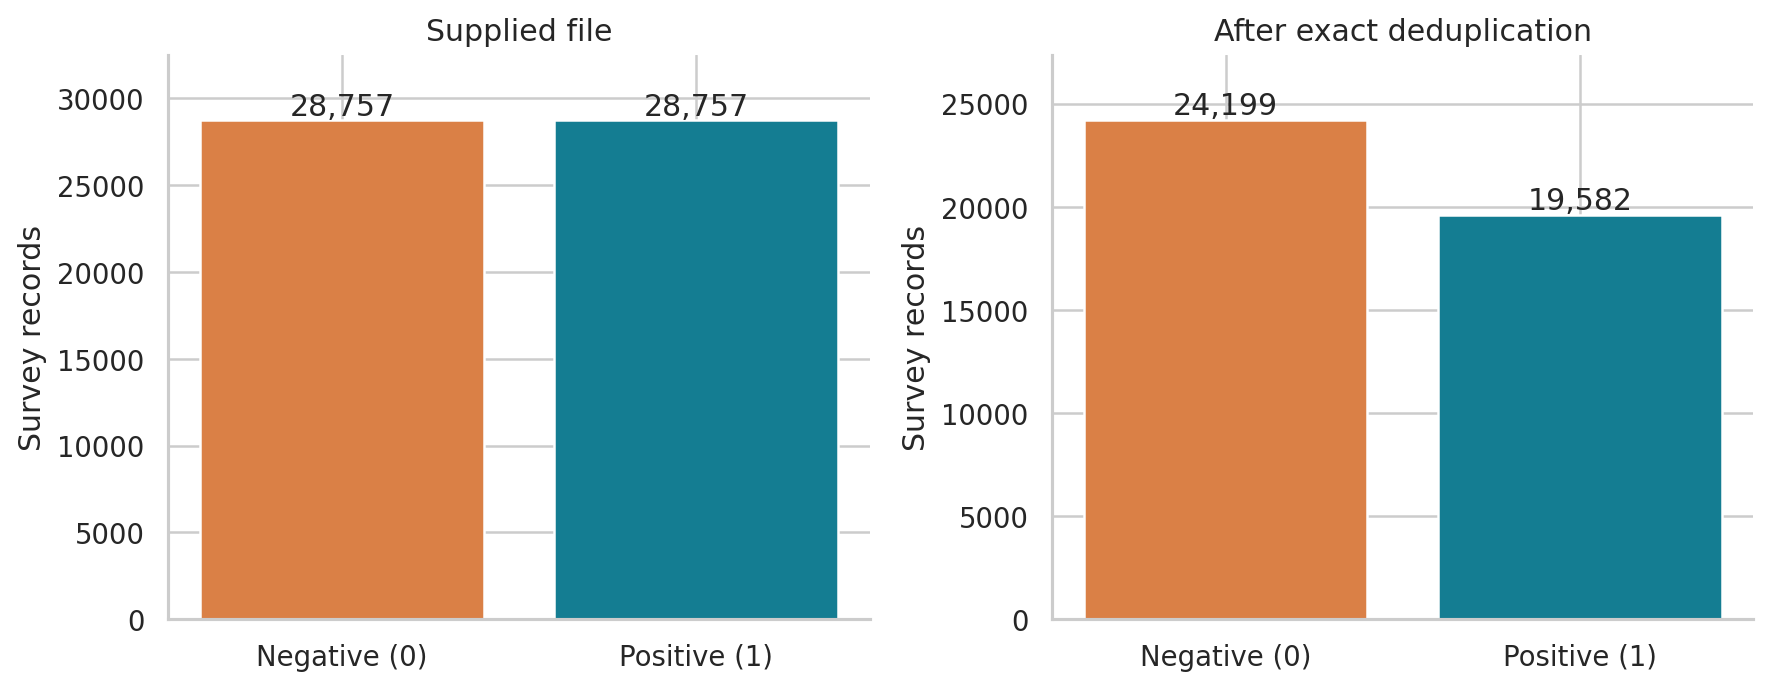

In [3]:
duplicate_count = int(raw.duplicated().sum())
data = raw.drop_duplicates().copy()
data.insert(0, 'source_row', data.index)
data.reset_index(drop=True, inplace=True)
TARGET = 'liked'
SENSITIVE = ['gender', 'age_group', 'nationality', 'education', 'household_income',
             'has_disability', 'uses_assistive_device', 'requested_special_assistance']
X = data.drop(columns=[TARGET, 'source_row'] + SENSITIVE)
y = data[TARGET].astype(int)
# Group by model inputs, so profiles made identical by demographic exclusion stay together.
groups = pd.util.hash_pandas_object(X, index=False).astype(str)
conflicts = pd.DataFrame({'group': groups, 'y': y}).groupby('group').y.nunique()
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
dev_idx, test_idx = next(outer.split(X, y, groups))
inner = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED + 1)
a, b = next(inner.split(X.iloc[dev_idx], y.iloc[dev_idx], groups.iloc[dev_idx]))
train_idx, val_idx = dev_idx[a], dev_idx[b]
X_train, X_val, X_test = [X.iloc[ix].copy() for ix in [train_idx, val_idx, test_idx]]
y_train, y_val, y_test = [y.iloc[ix].copy() for ix in [train_idx, val_idx, test_idx]]
g_train, g_val, g_test = [groups.iloc[ix] for ix in [train_idx, val_idx, test_idx]]
assert not (set(g_train) & set(g_val) or set(g_train) & set(g_test) or set(g_val) & set(g_test))
assert len(train_idx) + len(val_idx) + len(test_idx) == len(data)
split_manifest = data[['source_row', 'liked']].copy()
split_manifest['profile_group'] = groups
split_manifest['split'] = ''
for label, ix in [('train', train_idx), ('validation', val_idx), ('test', test_idx)]:
    split_manifest.loc[ix, 'split'] = label
split_manifest.to_csv(OUT / 'tables/split_manifest.csv', index=False)
split_summary = pd.DataFrame([{'split': n, 'rows': len(ix), 'positive_rate': y.iloc[ix].mean(),
    'unique_profiles': groups.iloc[ix].nunique()} for n, ix in [('train', train_idx), ('validation', val_idx), ('test', test_idx)]])
table(split_summary, 'split_summary')

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, frame, title in zip(axes, [raw, data], ['Supplied file', 'After exact deduplication']):
    counts = frame.liked.value_counts().sort_index()
    ax.bar(['Negative (0)', 'Positive (1)'], counts, color=['#DA8046','#147D92'])
    ax.set(title=title, ylabel='Survey records')
    ax.set_ylim(0, counts.max() * 1.13)
    for i, v in enumerate(counts): ax.text(i, v + 300, f'{v:,}', ha='center')
figure('01_class_balance')

**13,733 exact duplicates removed**; **43,781 records retained**. 881 modeled feature profiles have conflicting labels. The retained positive share is **44.7%**. No modeled profile overlaps splits.

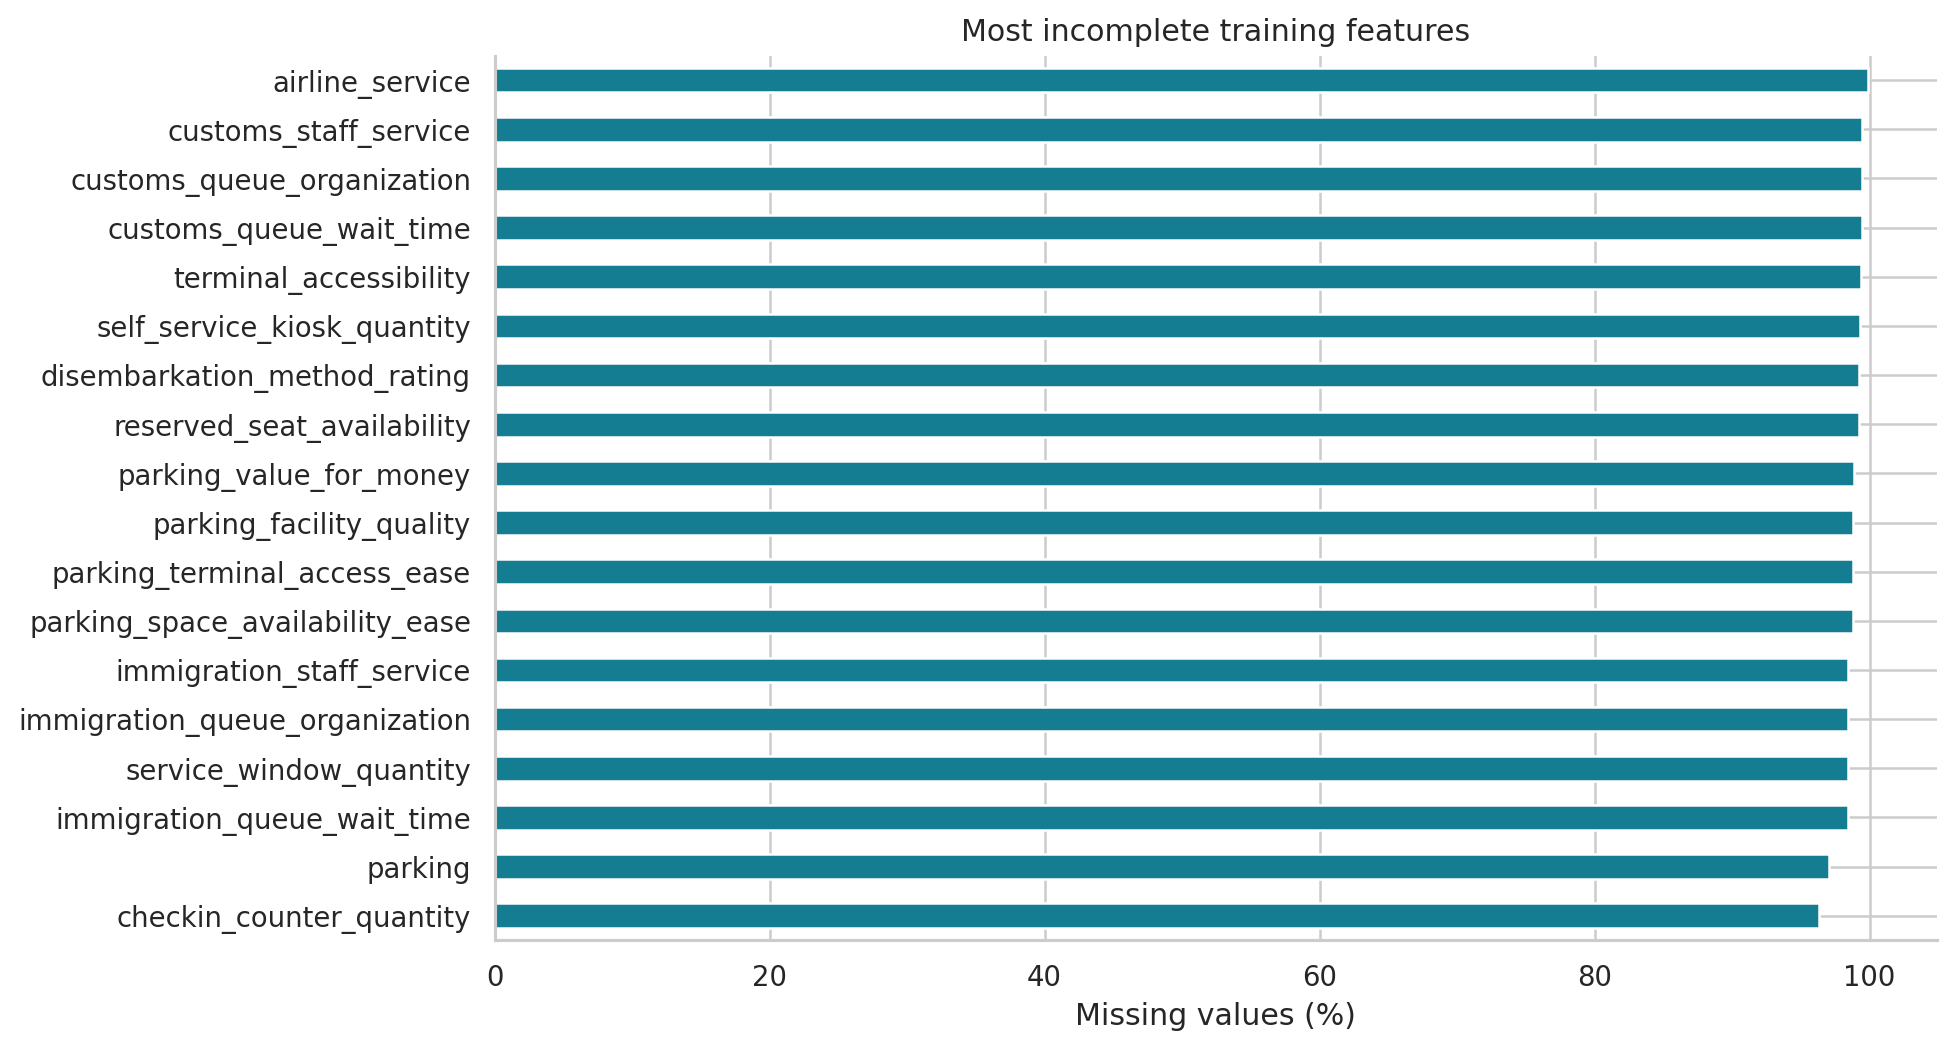

,feature,missing_fraction
0,airline_service,0.9989
1,customs_staff_service,0.9945
2,customs_queue_organization,0.9944
3,customs_queue_wait_time,0.9943
4,terminal_accessibility,0.9941
5,self_service_kiosk_quantity,0.9929
6,disembarkation_method_rating,0.9925
7,reserved_seat_availability,0.9922
8,parking_value_for_money,0.9884
9,parking_facility_quality,0.9883


,feature,observed,minimum,maximum,invalid_outside_1_5
0,disembarkation_method_rating,196,1.0,5.0,0
1,curbside_dropoff_ease,12485,1.0,5.0,0
2,transport_options_to_airport,10044,1.0,5.0,0
3,checkin_process,5028,1.0,5.0,0
4,checkin_queue_wait_time,1116,1.0,5.0,0
5,checkin_queue_organization,1097,1.0,5.0,0
6,self_service_kiosk_quantity,187,1.0,5.0,0
7,checkin_counter_quantity,963,1.0,5.0,0
8,staff_courtesy,967,1.0,5.0,0
9,checkin_service_time,966,1.0,5.0,0


,feature,applicable_but_missing,not_applicable_but_observed
28,retail_outlets,16409,0
46,airport_internet,14969,0
3,checkin_process,14844,0
24,food_beverage_outlets,10706,0
2,transport_options_to_airport,9828,0
10,ticket_purchase_process,9691,0
1,curbside_dropoff_ease,7387,0
12,security_screening_process,6614,0
49,restrooms,6367,0
45,power_outlet_availability,5513,0


In [4]:
train_data = data.iloc[train_idx]
missing = X_train.isna().mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(11, 6))
missing.head(18).sort_values().mul(100).plot.barh(ax=ax, color='#147D92')
ax.set(xlabel='Missing values (%)', title='Most incomplete training features')
figure('02_missingness')
table(pd.DataFrame({'feature':missing.index, 'missing_fraction':missing.values}), 'training_missingness')

TIME_COLS = ['arrival_lead_time', 'connection_wait_time']
RATINGS = [c for c in X.select_dtypes('number') if c not in TIME_COLS and not c.endswith('_is_applicable')]
FLAGS = [c for c in X if c.endswith('_is_applicable')]
rating_audit = pd.DataFrame([{'feature':c, 'observed':int(X_train[c].notna().sum()),
    'minimum':X_train[c].min(), 'maximum':X_train[c].max(),
    'invalid_outside_1_5':int((X_train[c].notna() & ~X_train[c].between(1,5)).sum())} for c in RATINGS])
table(rating_audit.head(10), 'rating_range_preview')
rating_audit.to_csv(OUT / 'tables/rating_range_audit.csv', index=False)
assert rating_audit.invalid_outside_1_5.sum() == 0
applicability_audit = []
for flag in FLAGS:
    base = flag.removesuffix('_is_applicable')
    applicability_audit.append({'feature':base,
        'applicable_but_missing':int(((X_train[flag]==1) & X_train[base].isna()).sum()),
        'not_applicable_but_observed':int(((X_train[flag]==0) & X_train[base].notna()).sum())})
table(pd.DataFrame(applicability_audit).sort_values('applicable_but_missing', ascending=False).head(10), 'applicability_preview')
pd.DataFrame(applicability_audit).to_csv(OUT / 'tables/applicability_audit.csv', index=False)

### Which service questions did passengers answer?

Compare boarding and disembarkation, then count how many ratings each passenger supplied. A missing rating can mean that the question did not apply or that the passenger skipped it.

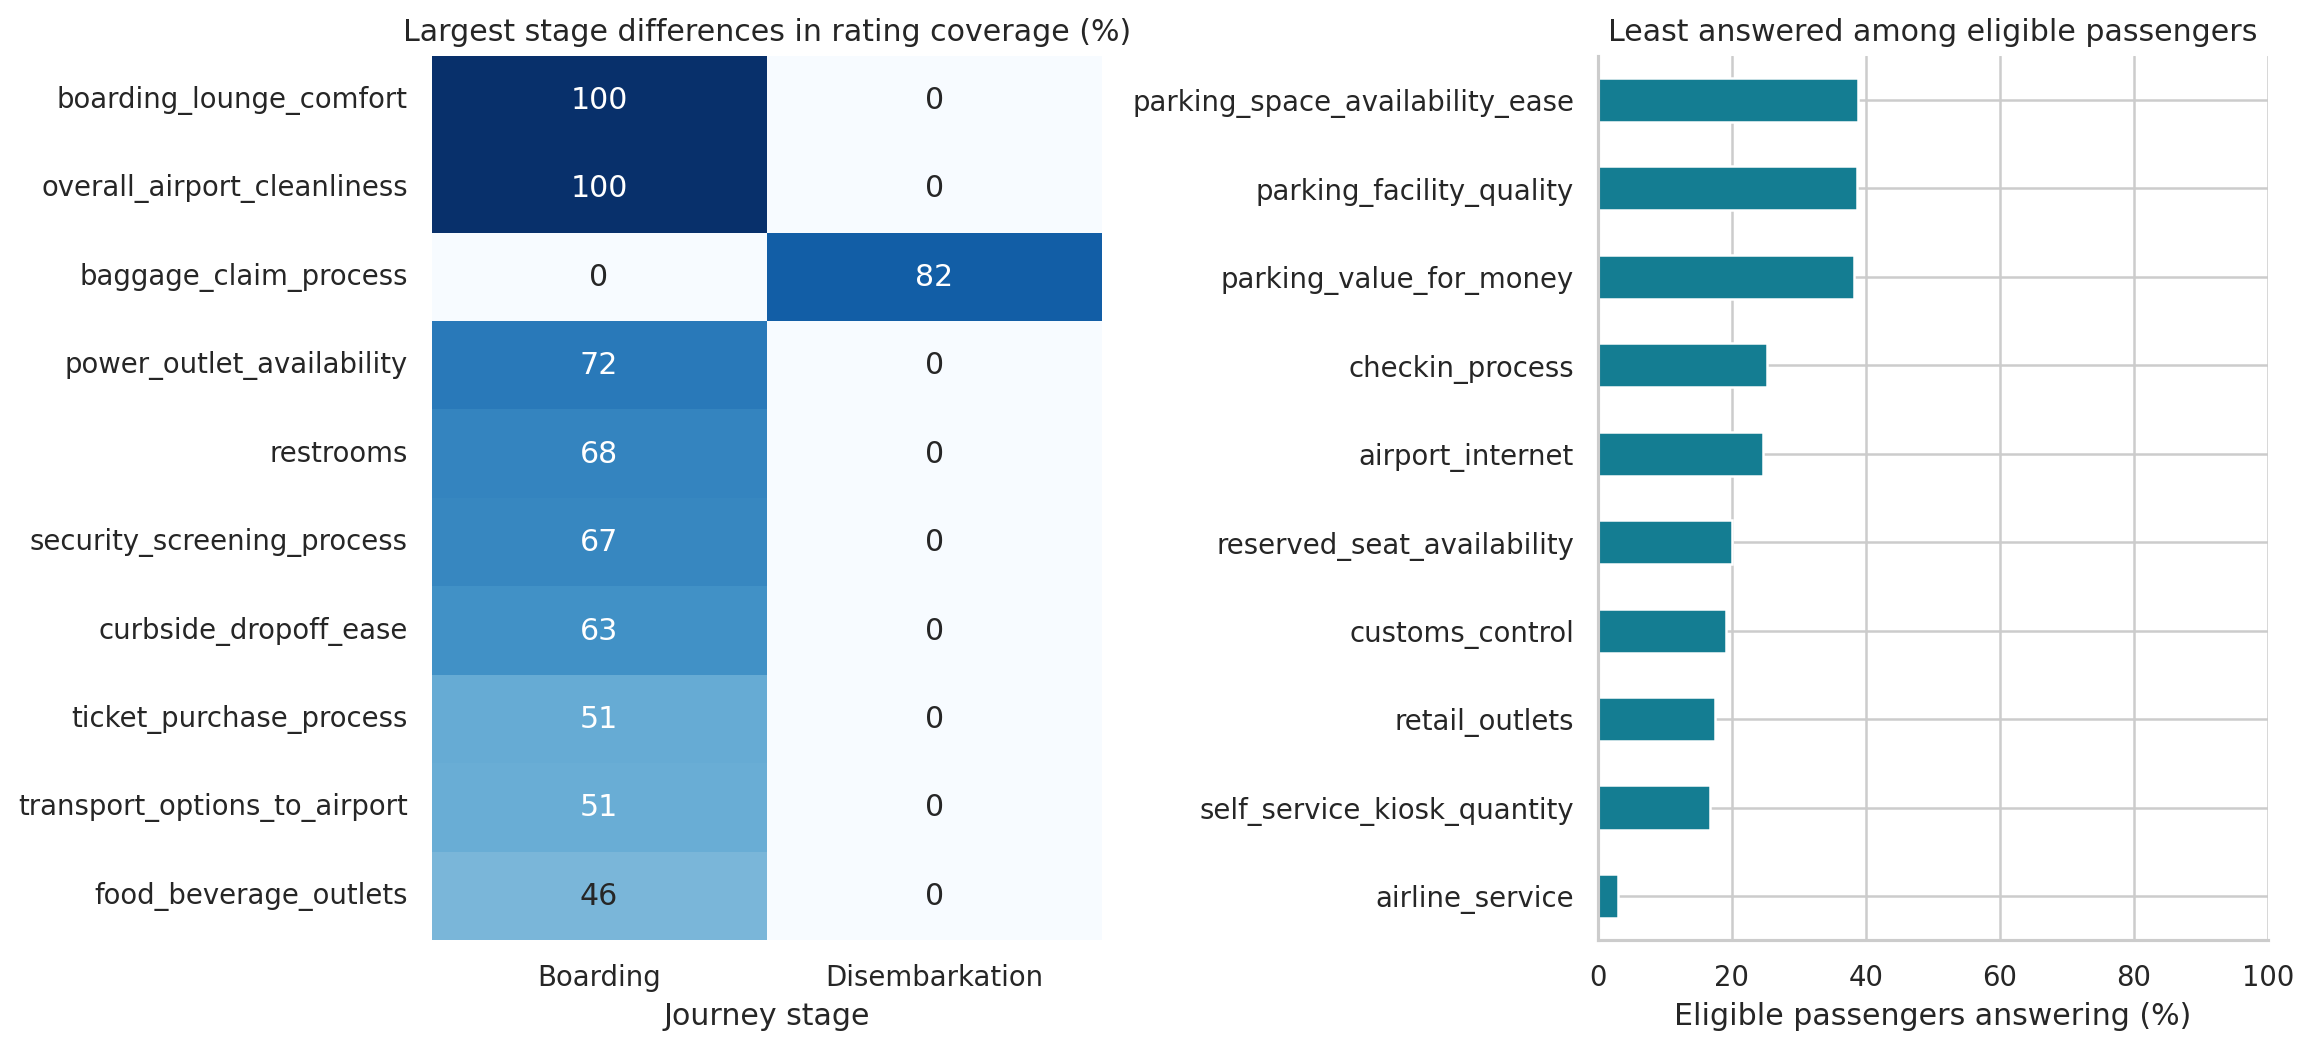

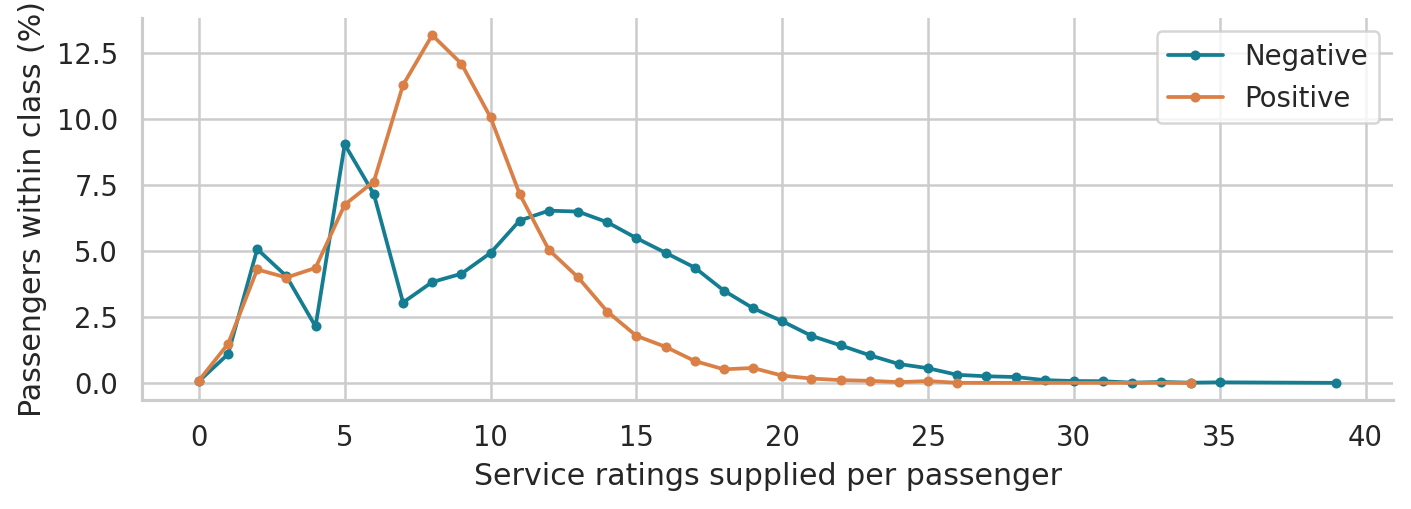

In [5]:
coverage = X_train[RATINGS].notna().groupby(X_train.process).mean().T
coverage['spread'] = coverage.max(axis=1) - coverage.min(axis=1)
coverage = coverage.sort_values('spread', ascending=False)
coverage.to_csv(OUT / 'tables/rating_coverage_by_process.csv')
paired = [c for c in RATINGS if c + '_is_applicable' in X_train]
eligible = pd.DataFrame({c: X_train[c + '_is_applicable'].eq(1) for c in paired})
response = pd.DataFrame({'eligible': eligible.sum(),
                         'answered': (eligible & X_train[paired].notna()).sum()})
response['answered_pct'] = 100 * response.answered / response.eligible.replace(0, np.nan)
response.to_csv(OUT / 'tables/eligible_response_rates.csv')

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
sns.heatmap(100 * coverage.drop(columns='spread').head(10), annot=True, fmt='.0f',
            cmap='Blues', vmin=0, vmax=100, cbar=False, ax=axes[0])
axes[0].set(title='Largest stage differences in rating coverage (%)', ylabel='', xlabel='Journey stage')
bottom = response.query('eligible >= 100').nsmallest(10, 'answered_pct').sort_values('answered_pct')
bottom.answered_pct.plot.barh(ax=axes[1], color='#147D92')
axes[1].set(title='Least answered among eligible passengers', xlabel='Eligible passengers answering (%)', xlim=(0, 100))
figure('02b_routing_and_response')

counts = X_train[RATINGS].notna().sum(axis=1)
fig, ax = plt.subplots(figsize=(8, 3))
for label, name in [(0, 'Negative'), (1, 'Positive')]:
    pct = counts[y_train.eq(label)].value_counts(normalize=True).sort_index().mul(100)
    ax.plot(pct.index, pct, marker='.', label=name)
ax.set(xlabel='Service ratings supplied per passenger', ylabel='Passengers within class (%)')
ax.legend()
figure('02c_survey_depth')

**What the coverage plot shows.** Boarding-lounge comfort was recorded for 99.9% of boarding surveys and 0% of disembarkation surveys. Baggage-claim process was recorded for 82.3% of disembarkation surveys and 0% of boarding surveys. Even among the 1,016 passengers marked eligible for the airline-service question, only 30 supplied a rating. These patterns motivate retaining both the applicability flag and whether a rating was observed.

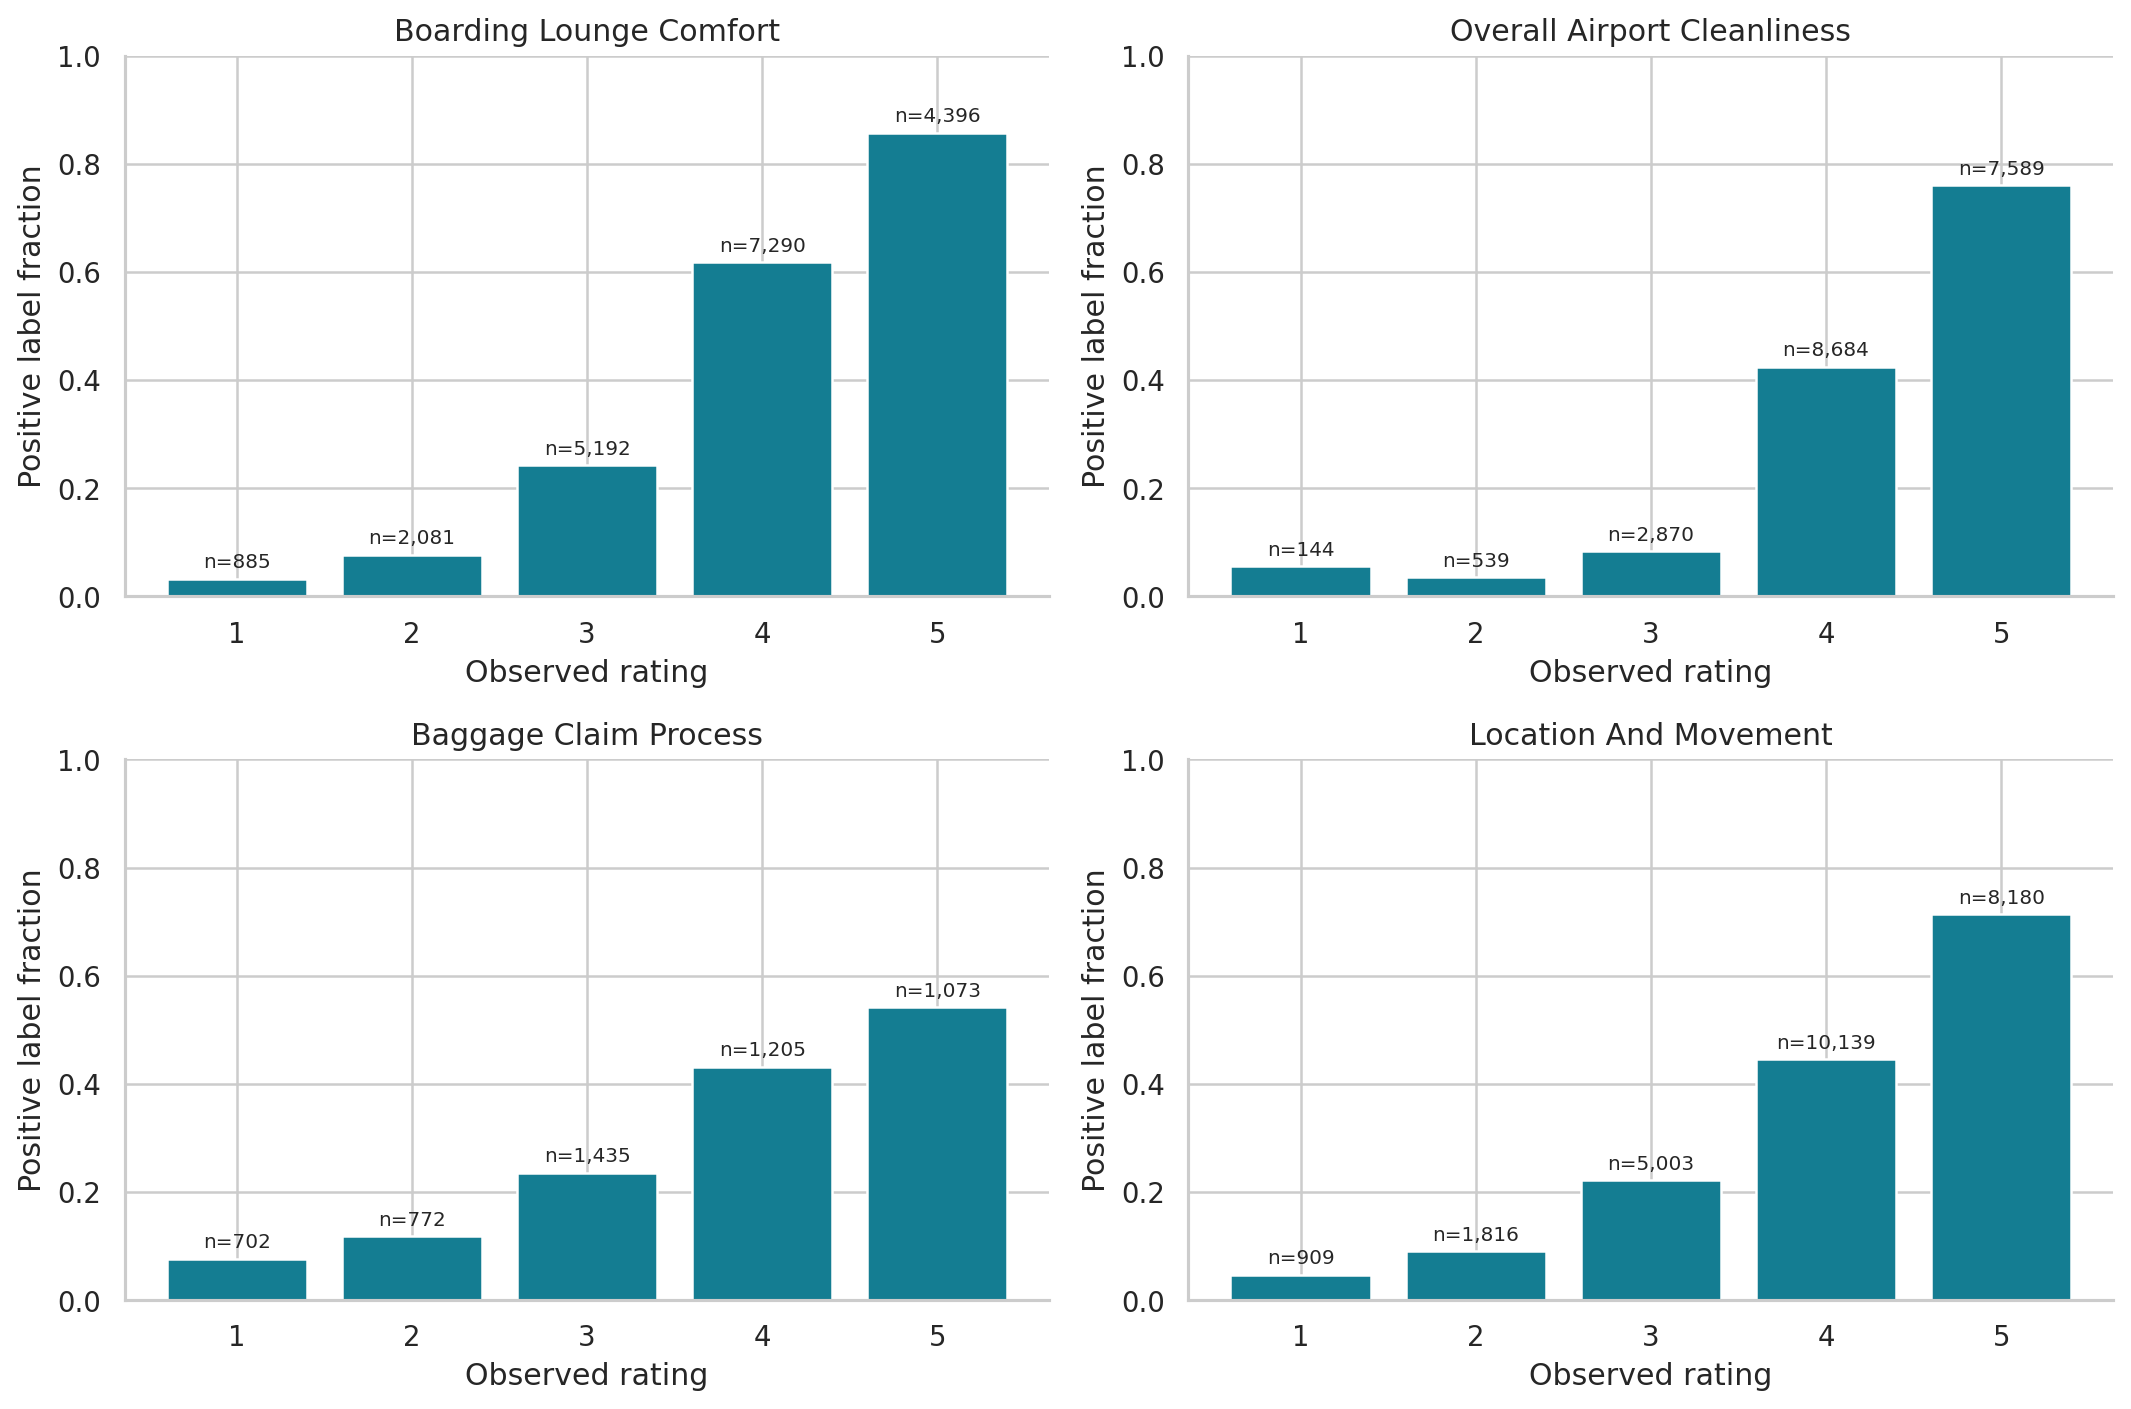

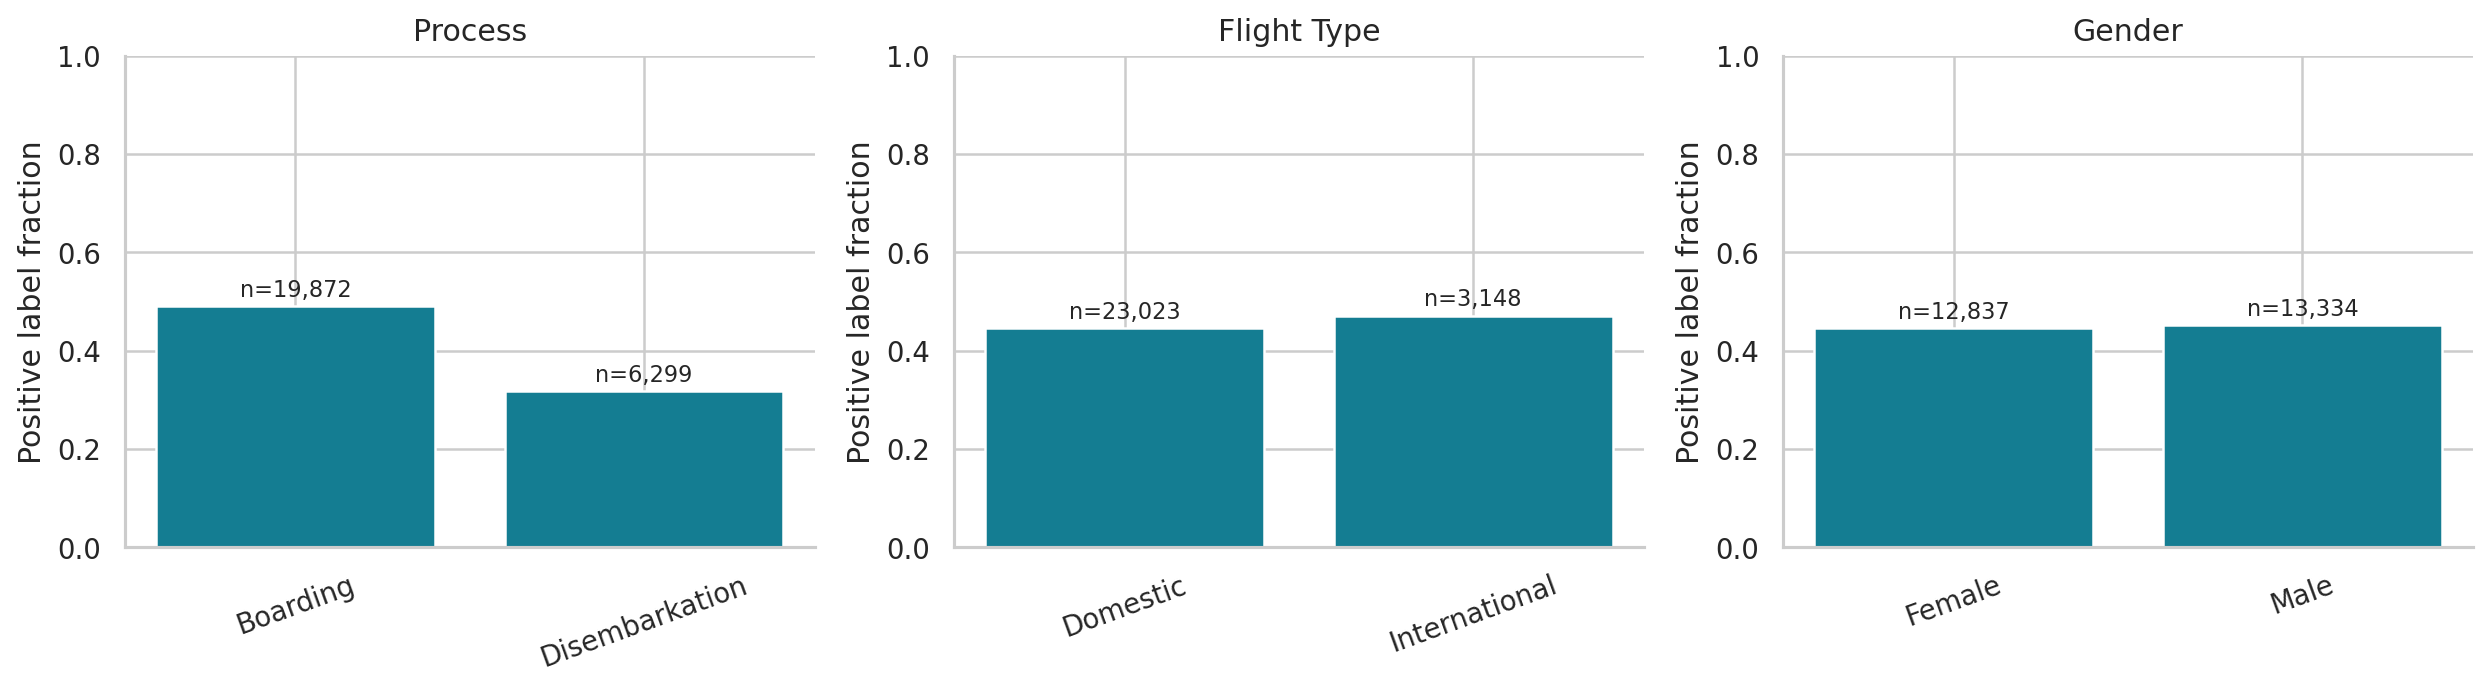

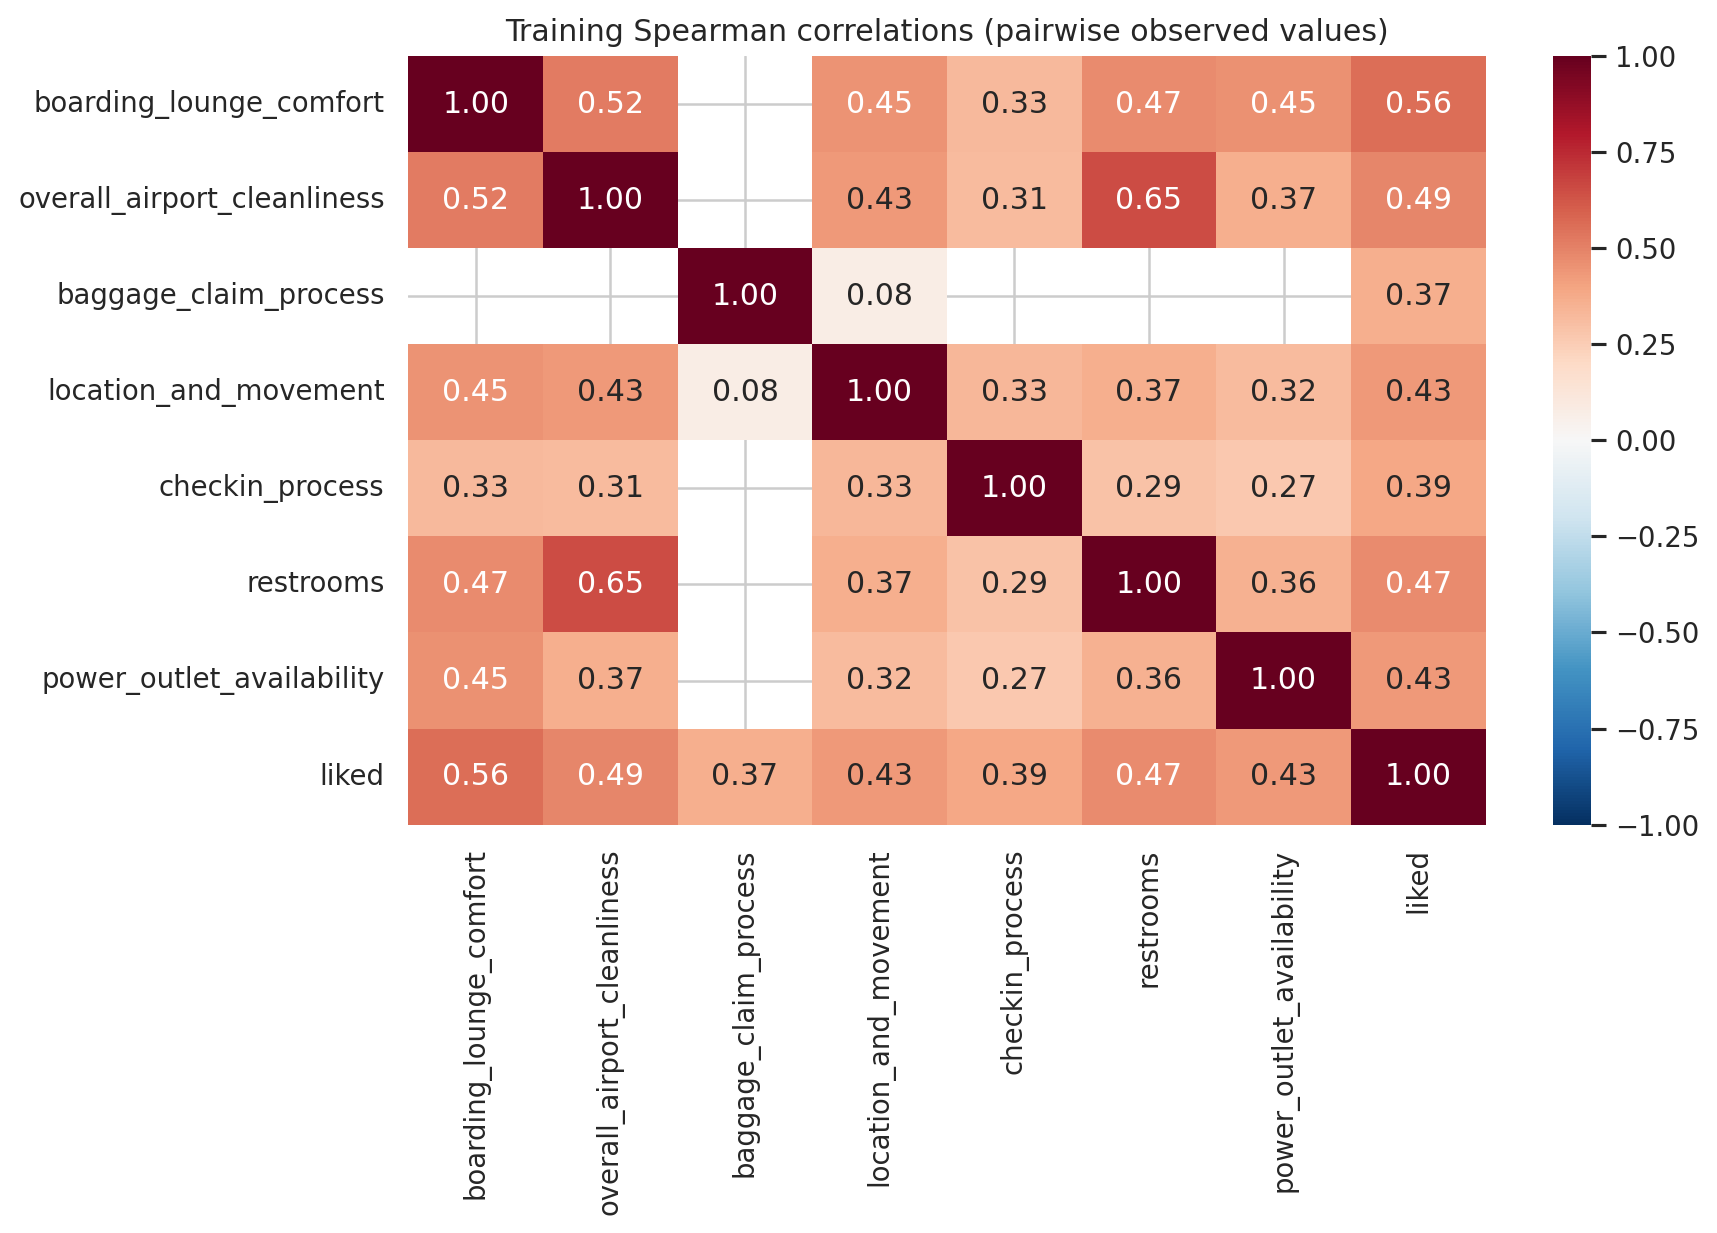

In [6]:
selected_ratings = ['boarding_lounge_comfort','overall_airport_cleanliness','baggage_claim_process','location_and_movement']
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, c in zip(axes.flat, selected_ratings):
    tmp = train_data.groupby(c).liked.agg(['mean','count']).reset_index()
    ax.bar(tmp[c], tmp['mean'], color='#147D92')
    ax.set(title=c.replace('_',' ').title(), xlabel='Observed rating', ylabel='Positive label fraction', ylim=(0,1))
    for _, r in tmp.iterrows(): ax.text(r[c], r['mean'] + .02, f"n={int(r['count']):,}", ha='center', fontsize=8)
figure('03_ratings_and_label')

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, c in zip(axes, ['process','flight_type','gender']):
    tmp = train_data.groupby(c).liked.agg(['mean','count']).reset_index()
    ax.bar(tmp[c], tmp['mean'], color='#147D92')
    ax.set(title=c.replace('_',' ').title(), ylabel='Positive label fraction', ylim=(0,1))
    ax.tick_params(axis='x', labelrotation=20)
    for j, r in tmp.iterrows(): ax.text(j, r['mean'] + .02, f"n={int(r['count']):,}", ha='center', fontsize=9)
figure('04_context_and_label')

corr_columns = selected_ratings + ['checkin_process','restrooms','power_outlet_availability','liked']
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(train_data[corr_columns].corr(method='spearman', min_periods=100), annot=True,
    fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title('Training Spearman correlations (pairwise observed values)')
figure('05_correlations')

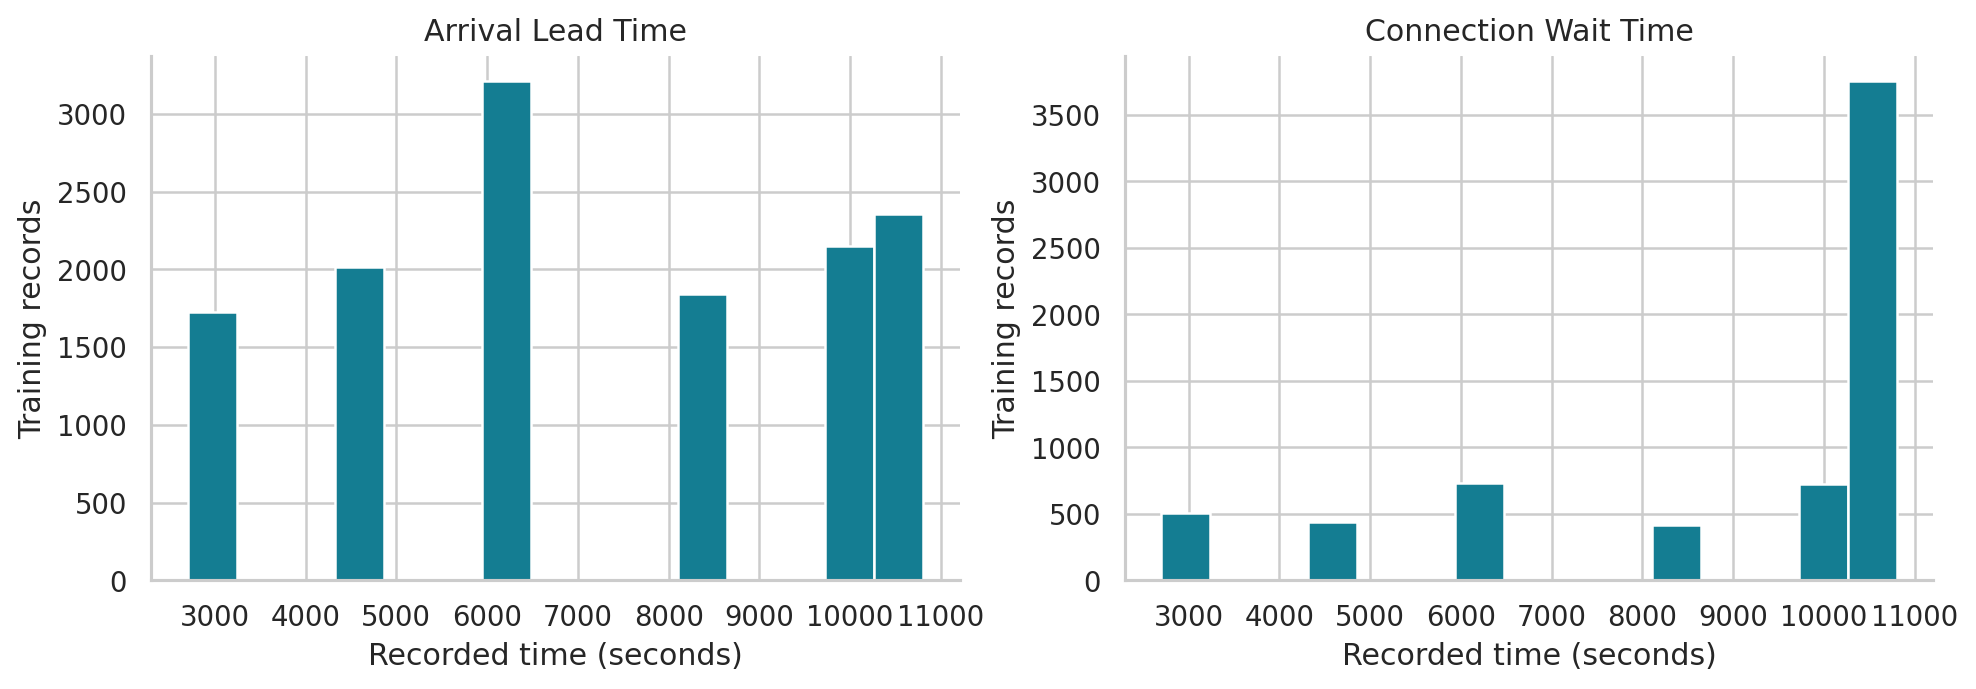

,feature,q1,q3,iqr,outside_iqr,q01,q99
0,arrival_lead_time,4500.0,9900.0,5400.0,0,2700.0,10800.0
1,connection_wait_time,6300.0,10800.0,4500.0,0,2700.0,10800.0


In [7]:
outliers=[]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, c in zip(axes, TIME_COLS):
    values=X_train[c].dropna(); q1,q3=values.quantile([.25,.75]); iqr=q3-q1
    outliers.append({'feature':c,'q1':q1,'q3':q3,'iqr':iqr,
        'outside_iqr':int(((values<q1-1.5*iqr)|(values>q3+1.5*iqr)).sum()),
        'q01':values.quantile(.01),'q99':values.quantile(.99)})
    ax.hist(values,bins=15,color='#147D92')
    ax.set(title=c.replace('_',' ').title(), xlabel='Recorded time (seconds)', ylabel='Training records')
figure('06_time_distributions')
table(pd.DataFrame(outliers),'outlier_audit')

## 4. Project plan and experimental protocol

Compare model families on the same validation passengers. Within each family, keep the version with the highest validation macro F1. Evaluate the overall winner on the test set and compare it with predicting the majority class. The original project already used this test partition.

## 5. Data preparation and feature engineering

Exclude eight demographic and assistance fields from prediction and retain them for the subgroup audit. Within training folds, impute and scale numeric values, clip only the two time fields, one-hot encode categories, and remove constants. Three summaries capture each passenger’s mean rating, response count, and fraction of ratings at 1–2. The polynomial experiment adds the squares and pairwise products of those summaries.

In [8]:
from sklearn.preprocessing import PolynomialFeatures
def make_pipeline(model, columns=None, engineered=True, polynomial=False):
    cols = list(X_train.columns if columns is None else columns)
    rating_cols = tuple(c for c in RATINGS if c in cols)
    times = [c for c in TIME_COLS if c in cols]
    num = [c for c in cols if pd.api.types.is_numeric_dtype(X_train[c]) and c not in times]
    cats = [c for c in cols if c not in num + times]
    if engineered and rating_cols:
        num += ['rating_mean','rating_count','low_rating_fraction']
    numeric = Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True, keep_empty_features=True)),
                        ('scale', StandardScaler())])
    timed = Pipeline([('clip', QuantileClipper()), ('impute', SimpleImputer(strategy='median', add_indicator=True, keep_empty_features=True)),
                      ('scale', StandardScaler())])
    categorical = Pipeline([('impute', SimpleImputer(strategy='constant', fill_value='__MISSING__')),
        ('encode', OneHotEncoder(handle_unknown='ignore', min_frequency=20, sparse_output=False))])
    preprocess = ColumnTransformer([('numeric', numeric, num), ('time', timed, times), ('categorical', categorical, cats)], remainder='drop')
    if polynomial:
        # Add only squares and interactions of the three summaries; retain every original input.
        summaries = ['rating_mean', 'rating_count', 'low_rating_fraction']
        quadratic = Pipeline([('impute', SimpleImputer(strategy='median')),
                              ('terms', PolynomialFeatures(degree=(2, 2), include_bias=False)),
                              ('scale', StandardScaler())])
        preprocess.transformers.append(('quadratic', quadratic, summaries))
    return Pipeline([('features', SurveyFeatures(rating_cols, enabled=bool(engineered and rating_cols))),
        ('preprocess', preprocess), ('constant_filter', VarianceThreshold()), ('model', model)])

prep_demo = make_pipeline(LogisticRegression(max_iter=1500, random_state=SEED))
prep_demo.fit(X_train, y_train)
transformed = prep_demo[:-1].transform(X_val)
assert np.isfinite(transformed).all()
print('Encoded nonconstant features:', transformed.shape[1])
print('Median imputer, encoder, clipping bounds, and scaler fitted on training only.')

Encoded nonconstant features: 278
Median imputer, encoder, clipping bounds, and scaler fitted on training only.


## 6. Model building and cross-validation

Start with a majority-class baseline. For the classical models, compare settings using three grouped folds from 3,000 randomly selected training profiles, then refit each winning setting on the full training split. The grid-search CSV contains the individual trials.

In [9]:
def metrics(y_true, prediction, score):
    return {'accuracy':accuracy_score(y_true,prediction),
        'balanced_accuracy':balanced_accuracy_score(y_true,prediction),
        'precision':precision_score(y_true,prediction,zero_division=0),
        'recall':recall_score(y_true,prediction,zero_division=0),
        'f1':f1_score(y_true,prediction,zero_division=0),
        'macro_f1':f1_score(y_true,prediction,average='macro',zero_division=0),
        'roc_auc':roc_auc_score(y_true,score), 'average_precision':average_precision_score(y_true,score)}
def model_score(model, frame):
    return model.predict_proba(frame)[:,1] if hasattr(model,'predict_proba') else model.decision_function(frame)

models, validation_rows, train_rows, fit_seconds = {}, [], [], {}
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import Perceptron
from sklearn.svm import LinearSVC
from xgboost import XGBClassifier

logit = LogisticRegression(max_iter=1200, random_state=SEED)
hist = HistGradientBoostingClassifier(max_iter=160, learning_rate=.08, l2_regularization=1,
                                      early_stopping=False, random_state=SEED)
grid_specs = {
    'Majority baseline': (DummyClassifier(strategy='most_frequent'), {}),
    'Logistic regression': (logit, {'model__C': [.25, 1]}),
    'Polynomial logistic': (logit, {'model__C': [.25, 1]}),
    'ANOVA logistic': (logit, {'select__percentile': [25, 50], 'model__C': [.25, 1]}),
    'L1-selected logistic': (logit, {'select__estimator__C': [.05, .2], 'model__C': [.25, 1]}),
    'Perceptron': (Perceptron(penalty='l2', random_state=SEED), {'model__alpha': [.0001, .001]}),
    'Decision tree': (DecisionTreeClassifier(min_samples_leaf=10, random_state=SEED), {'model__max_depth': [6, 12]}),
    'KNN': (KNeighborsClassifier(weights='distance'), {'model__n_neighbors': [11, 21]}),
    'Linear SVM': (LinearSVC(random_state=SEED), {'model__C': [.1, 1]}),
    'RBF SVM': (SVC(kernel='rbf', cache_size=512), {'model__C': [1, 2]}),
    'Random forest': (RandomForestClassifier(n_estimators=100, n_jobs=2, random_state=SEED), {'model__min_samples_leaf': [2, 5]}),
    'Bagging': (BaggingClassifier(n_estimators=30, random_state=SEED), {'model__max_samples': [.6, .8]}),
    'AdaBoost': (AdaBoostClassifier(n_estimators=90, random_state=SEED), {'model__learning_rate': [.3, .8]}),
    'Histogram boosting': (hist, {'model__max_leaf_nodes': [15, 31]}),
    'XGBoost': (XGBClassifier(n_estimators=160, learning_rate=.08, tree_method='hist', n_jobs=2, random_state=SEED),
                {'model__max_depth': [3, 5]}),
}
CONTEXT = ['process','month','flight_type','connection','ticket_purchased_by',
    'ticket_purchase_channel','transport_to_airport','checkin_method','traveling_alone',
    'number_of_companions','trip_purpose','trips_last_12_months','used_airport_before_last_12_months']

grid_specs['Boosting without aggregates'] = (hist, {'model__max_leaf_nodes': [15, 31]})
grid_specs['Context-only boosting'] = (hist, {'model__max_leaf_nodes': [15, 31]})
grid_models, grids = {}, []
profile_sample = np.random.default_rng(SEED).permutation(g_train.unique())[:3000]
idx = np.flatnonzero(g_train.isin(profile_sample))
folds = list(StratifiedGroupKFold(3, shuffle=True, random_state=SEED).split(X_train.iloc[idx], y_train.iloc[idx], g_train.iloc[idx]))
for name, (estimator, grid) in grid_specs.items():
    started = time.perf_counter()
    pipe = make_pipeline(clone(estimator), columns=CONTEXT if name == 'Context-only boosting' else None,
                         engineered=name not in ['Context-only boosting', 'Boosting without aggregates'],
                         polynomial=name == 'Polynomial logistic')
    if name == 'ANOVA logistic':
        pipe.steps.insert(-1, ('select', SelectPercentile(f_classif)))
    if name == 'L1-selected logistic':
        selector = LogisticRegression(penalty='l1', solver='liblinear', random_state=SEED)
        pipe.steps.insert(-1, ('select', SelectFromModel(selector)))
    search = GridSearchCV(pipe, grid, cv=folds, scoring='f1_macro', refit=False, error_score='raise', n_jobs=1)
    search.fit(X_train.iloc[idx], y_train.iloc[idx])
    grids.append(pd.DataFrame(search.cv_results_).assign(model=name))
    model = pipe.set_params(**search.best_params_).fit(X_train, y_train)
    grid_models[name] = model
    label = name
    models[label] = model
    validation_rows.append({'model': label, **metrics(y_val, model.predict(X_val), model_score(model, X_val))})

    fit_seconds[label] = time.perf_counter() - started
pd.concat(grids, ignore_index=True).to_csv(OUT / 'tables/classical_grid.csv', index=False)
specs = {name: model for name, (model, _) in grid_specs.items()}


### Stacking

A decision tree and KNN each produce a prediction. Logistic regression learns how to combine their predictions using training profiles held out from each base model’s fit.

In [10]:
stack = GroupedStackingClassifier([(name, clone(models[name])) for name in ['Decision tree', 'KNN']])
started = time.perf_counter()
stack.fit(X_train, y_train, groups=g_train)
name = 'Stacking'
models[name] = stack
validation_rows.append({'model': name, **metrics(y_val, stack.predict(X_val), model_score(stack, X_val))})
train_rows.append({'model': name, **metrics(y_train, stack.predict(X_train), model_score(stack, X_train))})
fit_seconds[name] = time.perf_counter() - started

### How does changing the neural network affect predictions?

The starting network has two hidden layers with 64 and 32 neurons. It uses ReLU activation and the Adam optimizer. Each row below changes one setting. A training pass through the data is an **epoch**. We restore the epoch with the lowest loss on the early-stopping subset. **Validation macro F1** averages the F1 scores for satisfied and dissatisfied passengers. Higher is better.

In [11]:
import tensorflow as tf
from tensorflow import keras
tf.config.threading.set_intra_op_parallelism_threads(4)
tf.config.threading.set_inter_op_parallelism_threads(2)
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
nn_fit,nn_stop=next(StratifiedGroupKFold(5,shuffle=True,random_state=SEED+5).split(X_train,y_train,g_train))
nn_preprocessor=make_pipeline(LogisticRegression())[:-1]
Z_fit=nn_preprocessor.fit_transform(X_train.iloc[nn_fit],y_train.iloc[nn_fit]).astype('float32')
Z_stop=nn_preprocessor.transform(X_train.iloc[nn_stop]).astype('float32')
def batches(x, y, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((x, np.asarray(y, dtype='float32')))
    if shuffle:
        ds = ds.shuffle(len(y), seed=SEED, reshuffle_each_iteration=True)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 2
    return ds.batch(256).with_options(options)

def infer(net, x):
    return np.concatenate([net(x[i:i+512], training=False).numpy().ravel() for i in range(0, len(x), 512)])

Z_val = nn_preprocessor.transform(X_val).astype('float32')
reference = dict(units=(64, 32), activation='relu', optimizer='adam', dropout=0., normalize=False, schedule=False)
trials = {
    'Starting network': {},
    'Wider layers (128, 64)': {'units': (128, 64)},
    'Third hidden layer (64, 32, 16)': {'units': (64, 32, 16)},
    'Tanh activation': {'activation': 'tanh'},
    'RMSprop optimizer': {'optimizer': 'rmsprop'},
    'Dropout (20%)': {'dropout': .2},
    'Batch normalization': {'normalize': True},
    'Reduce step size when progress stalls': {'schedule': True},
}
neural_rows = []
best_nn_f1 = -1
for label, change in trials.items():
    cfg = reference | change
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    net = keras.Sequential([keras.layers.Input(shape=(Z_fit.shape[1],))])
    for width in cfg['units']:
        net.add(keras.layers.Dense(width, use_bias=not cfg['normalize']))
        if cfg['normalize']:
            net.add(keras.layers.BatchNormalization())
        net.add(keras.layers.Activation(cfg['activation']))
        if cfg['dropout']:
            net.add(keras.layers.Dropout(cfg['dropout']))
    net.add(keras.layers.Dense(1, activation='sigmoid'))
    net.compile(optimizer=cfg['optimizer'], loss='binary_crossentropy')
    callbacks = [keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True)]
    if cfg['schedule']:
        callbacks.insert(0, keras.callbacks.ReduceLROnPlateau(patience=2, factor=.5, min_lr=1e-5))
    history = net.fit(batches(Z_fit, y_train.iloc[nn_fit], True),
                      validation_data=batches(Z_stop, y_train.iloc[nn_stop]), epochs=35,
                      shuffle=False, callbacks=callbacks, verbose=0)
    scores = infer(net, Z_val)
    row = metrics(y_val, scores >= .5, scores)
    neural_rows.append({'change': label, **cfg, 'best_epoch': 1 + np.argmin(history.history['val_loss']), **row})
    if row['macro_f1'] > best_nn_f1:
        best_nn_f1, best_nn_setting, best_nn_row = row['macro_f1'], label, row
        net.save(OUT/'models/best_network.keras')
keras_results = pd.DataFrame(neural_rows)
keras_results.to_csv(OUT/'tables/keras_experiments.csv', index=False)
display(keras_results[['change','best_epoch','macro_f1']].rename(columns={
    'change':'Change from starting network', 'best_epoch':'Best epoch', 'macro_f1':'Validation macro F1'}).round(4))
validation_rows.append({'model':'Dense neural network', **best_nn_row})
joblib.dump(nn_preprocessor, OUT/'models/neural_preprocessor.joblib')


,Change from starting network,Best epoch,Validation macro F1
0,Starting network,2,0.8221
1,"Wider layers (128, 64)",2,0.8271
2,"Third hidden layer (64, 32, 16)",2,0.8260
3,Tanh activation,5,0.8249
4,RMSprop optimizer,2,0.8250
5,Dropout (20%),5,0.8265
6,Batch normalization,5,0.8255
7,Reduce step size when progress stalls,8,0.8295


## 7. Optimization and feature selection

Tune the strongest boosting model using three folds of the full training split. For logistic regression, compare using every feature with two ways to select a smaller set. ANOVA ranks features individually by how their values differ between the two classes. L1 shrinks some logistic-regression coefficients to zero.

In [12]:
full_cv=list(StratifiedGroupKFold(3,shuffle=True,random_state=SEED+2).split(X_train,y_train,g_train))
boost_grid=GridSearchCV(make_pipeline(HistGradientBoostingClassifier(max_iter=180,learning_rate=.08,early_stopping=False,random_state=SEED)),
    {'model__max_leaf_nodes':[15,31],'model__l2_regularization':[1.,10.]},scoring='f1_macro',cv=full_cv,n_jobs=1,return_train_score=True,error_score='raise')
boost_grid.fit(X_train, y_train)
models['Tuned histogram boosting'] = boost_grid.best_estimator_
validation_rows.append({'model':'Tuned histogram boosting', **metrics(y_val, boost_grid.predict(X_val), model_score(boost_grid,X_val))})
pd.DataFrame(boost_grid.cv_results_).to_csv(OUT/'tables/grid_tuned_histogram_boosting.csv', index=False)


### Does feature selection help?

Compare the number of encoded inputs and validation macro F1 against logistic regression using all features.

In [13]:
selection = []
for name in ['Logistic regression', 'Polynomial logistic', 'ANOVA logistic', 'L1-selected logistic']:
    pipe = grid_models[name]
    names = pipe['preprocess'].get_feature_names_out()[pipe['constant_filter'].get_support()]
    if 'select' in pipe.named_steps:
        names = names[pipe['select'].get_support()]
    selection.append({'model': name, 'features': len(names),
                      'validation_macro_f1': next(r['macro_f1'] for r in validation_rows if r['model'] == name)})
    pd.Series(names, name='encoded_feature').to_csv(OUT / 'tables' / (name + '_features.csv'), index=False)
selection = pd.DataFrame(selection)
selection['delta_vs_plain'] = selection.validation_macro_f1 - selection.validation_macro_f1.iloc[0]
table(selection, 'feature_selection_comparison')

,model,features,validation_macro_f1,delta_vs_plain
0,Logistic regression,278,0.8291,0.0000
1,Polynomial logistic,284,0.8288,-0.0003
2,ANOVA logistic,139,0.8274,-0.0017
3,L1-selected logistic,146,0.8296,0.0005


In [14]:
families = {
    'Baseline': ['Majority baseline'],
    'Logistic regression': ['Logistic regression', 'Polynomial logistic', 'ANOVA logistic', 'L1-selected logistic'],
    'Decision tree': ['Decision tree'], 'Nearest neighbors': ['KNN'],
    'Support vector machine': ['Linear SVM', 'RBF SVM'], 'Perceptron': ['Perceptron'],
    'Bagging': ['Bagging'], 'Random forest': ['Random forest'], 'AdaBoost': ['AdaBoost'],
    'Histogram boosting': ['Histogram boosting', 'Tuned histogram boosting'],
    'XGBoost': ['XGBoost'], 'Stacking': ['Stacking'], 'Neural network': ['Dense neural network'],
}
all_scores = pd.DataFrame(validation_rows).set_index('model')
all_scores.to_csv(OUT/'tables/validation_trials.csv')
leaders = []
for family, names in families.items():
    winner = all_scores.loc[names, 'macro_f1'].idxmax()
    setting = best_nn_setting if family == 'Neural network' else winner
    leaders.append({'family': family, 'model': winner, 'setting': setting,
                    'validation_macro_f1': all_scores.loc[winner, 'macro_f1']})
comparison = pd.DataFrame(leaders).sort_values('validation_macro_f1', ascending=False)
comparison.to_csv(OUT/'tables/model_family_comparison.csv', index=False)
display(comparison[['family','setting','validation_macro_f1']].round(4))
best_name = comparison.iloc[0].model
print('Selected on validation:', best_name)


Selected on validation: Tuned histogram boosting


,family,setting,validation_macro_f1
9,Histogram boosting,Tuned histogram boosting,0.8330
10,XGBoost,XGBoost,0.8299
1,Logistic regression,L1-selected logistic,0.8296
12,Neural network,Reduce step size when progress stalls,0.8295
11,Stacking,Stacking,0.8292
4,Support vector machine,Linear SVM,0.8268
7,Random forest,Random forest,0.8264
2,Decision tree,Decision tree,0.8230
8,AdaBoost,AdaBoost,0.8218
6,Bagging,Bagging,0.8214


## 8. Locked test evaluation

Evaluate the selected model using its default decision rule. Report the majority-class baseline alongside it. The confusion matrix shows how many satisfied and dissatisfied passengers the model classified correctly.

,model,accuracy,balanced_accuracy,precision,recall,f1,macro_f1,roc_auc,average_precision
0,Tuned histogram boosting,0.8386,0.8383,0.8088,0.8352,0.8218,0.8372,0.9177,0.8972
1,Majority baseline,0.5545,0.5000,0.0000,0.0000,0.0000,0.3567,0.5000,0.4455


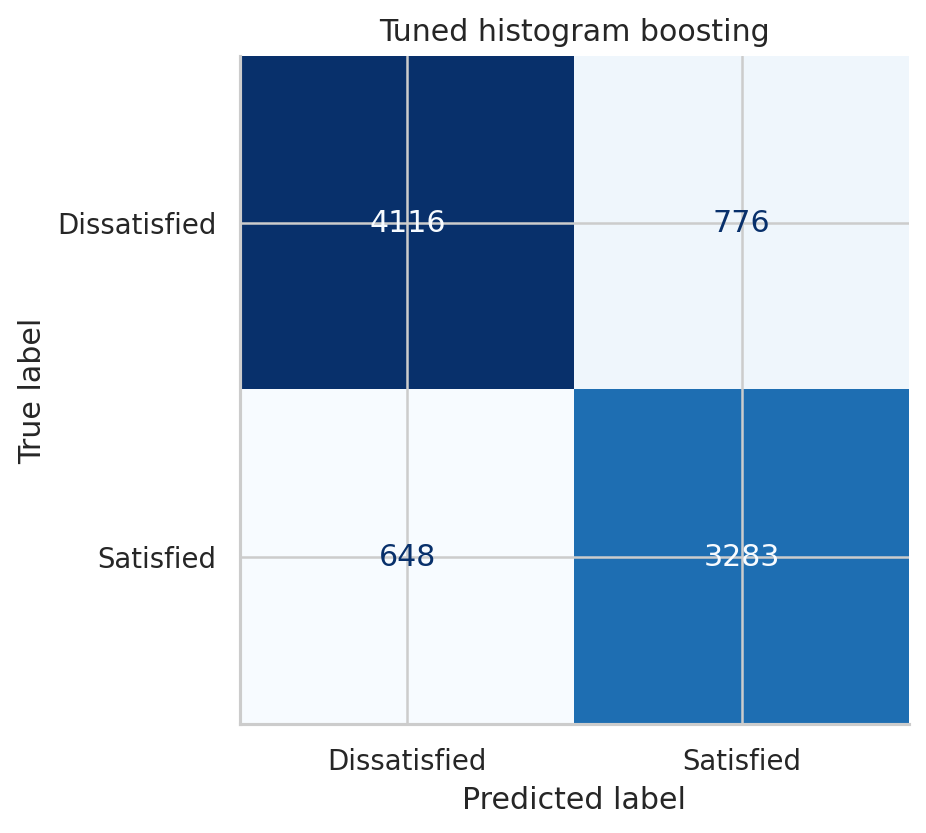

In [15]:
def test_predictions(name):
    if name == 'Dense neural network':
        net = keras.models.load_model(OUT/'models/best_network.keras')
        score = infer(net, nn_preprocessor.transform(X_test).astype('float32'))
        return score >= .5, score
    return models[name].predict(X_test), model_score(models[name], X_test)

chosen_pred, chosen_score = test_predictions(best_name)
is_probability = best_name == 'Dense neural network' or hasattr(models.get(best_name), 'predict_proba')
base_pred, base_score = test_predictions('Majority baseline')
test_results = pd.DataFrame([{'model': best_name, **metrics(y_test, chosen_pred, chosen_score)},
                             {'model': 'Majority baseline', **metrics(y_test, base_pred, base_score)}]).drop_duplicates('model')
table(test_results, 'test_results')
ConfusionMatrixDisplay.from_predictions(y_test, chosen_pred, display_labels=['Dissatisfied','Satisfied'], cmap='Blues', colorbar=False)
plt.title(best_name)
figure('10_confusion_matrix')


Selected-model probability metrics: {'brier_score': np.float64(0.11373812651742027), 'log_loss': 0.36277150149228105}


,metric,estimate,lower_95,upper_95
0,macro_f1,0.8372,0.8291,0.8449
1,roc_auc,0.9177,0.9120,0.9234


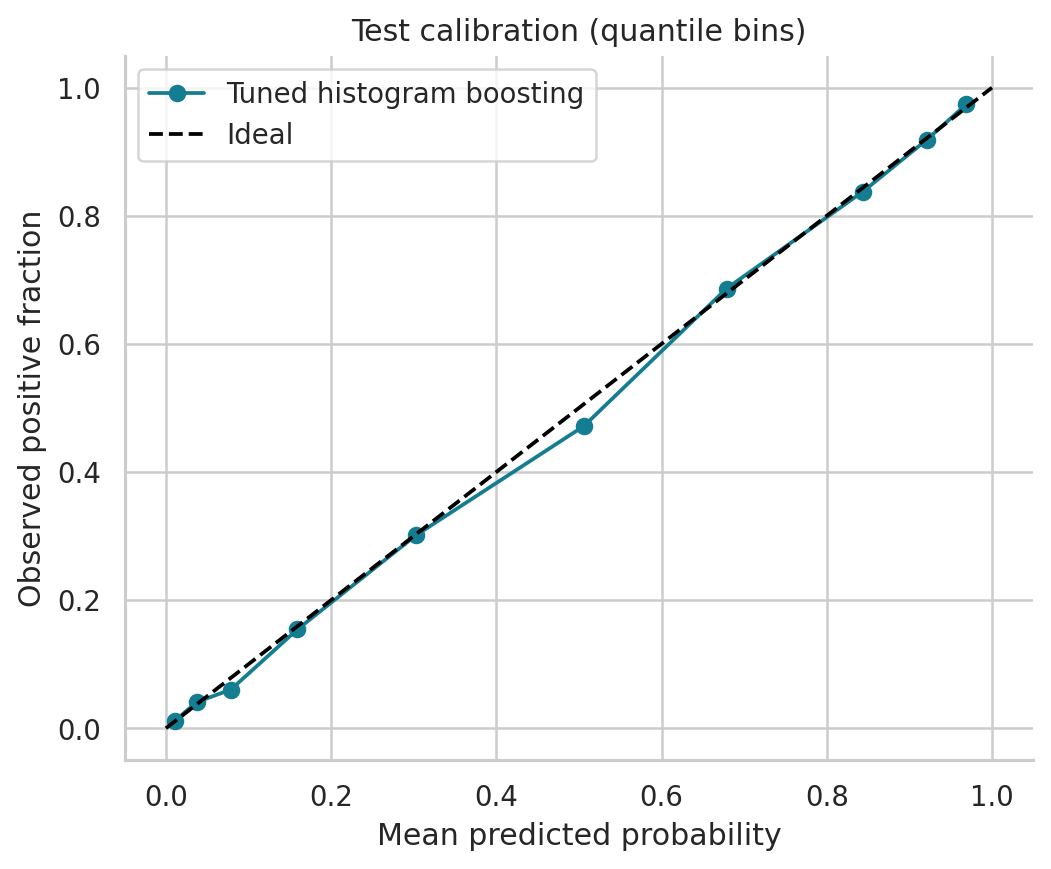

In [16]:
# Cluster bootstrap: keep conflicting-label rows from the same profile together.
# Intervals condition on this fitted model and sampled dataset; they do not cover
# unknown airports, temporal shifts, or model-selection uncertainty.
test_group_array=g_test.to_numpy()
unique_test_groups=pd.unique(test_group_array)
group_rows={g:np.flatnonzero(test_group_array==g) for g in unique_test_groups}
rng=np.random.default_rng(SEED+4); boot=[]
for iteration in range(500):
    ix=np.concatenate([group_rows[g] for g in rng.choice(unique_test_groups,len(unique_test_groups),replace=True)])
    boot.append({'macro_f1':f1_score(y_test.iloc[ix],chosen_pred[ix],average='macro'),
        'roc_auc':roc_auc_score(y_test.iloc[ix],chosen_score[ix])})
intervals=pd.DataFrame([{'metric':c,'estimate':float(test_results.set_index('model').loc[best_name,c]),
    'lower_95':float(pd.DataFrame(boot)[c].quantile(.025)),
    'upper_95':float(pd.DataFrame(boot)[c].quantile(.975))} for c in ['macro_f1','roc_auc']])
table(intervals,'bootstrap_intervals')
if is_probability:
    calibration_metrics={'brier_score':brier_score_loss(y_test,chosen_score),'log_loss':log_loss(y_test,chosen_score)}
    print('Selected-model probability metrics:',calibration_metrics)
    frac_pos,mean_pred=calibration_curve(y_test,chosen_score,n_bins=10,strategy='quantile')
    calibration=pd.DataFrame({'mean_predicted':mean_pred,'observed_positive_fraction':frac_pos})
    calibration.to_csv(OUT/'tables/calibration.csv',index=False)
    fig,ax=plt.subplots(figsize=(6,5)); ax.plot(mean_pred,frac_pos,'o-',label=best_name); ax.plot([0,1],[0,1],'k--',label='Ideal')
    ax.set(xlabel='Mean predicted probability',ylabel='Observed positive fraction',title='Test calibration (quantile bins)'); ax.legend()
    figure('12_calibration')

## 9. Interpretation, error analysis, and fairness

Which survey questions matter most to the strongest classical model? Shuffle one question at a time and measure the change in validation macro F1. Then compare the selected model’s test errors by group alongside the number of passengers in each group.

,feature,importance_mean,importance_std
48,location_and_movement,0.0279,0.0030
65,overall_airport_cleanliness,0.0216,0.0035
57,power_outlet_availability,0.0157,0.0009
52,boarding_lounge_comfort,0.0152,0.0061
53,thermal_comfort,0.0099,0.0058
11,transport_options_to_airport,0.0085,0.0025
49,signage,0.0079,0.0017
58,airport_internet,0.0062,0.0017
67,baggage_carousel_identification_ease,0.0055,0.0021
66,baggage_claim_process,0.0048,0.0028


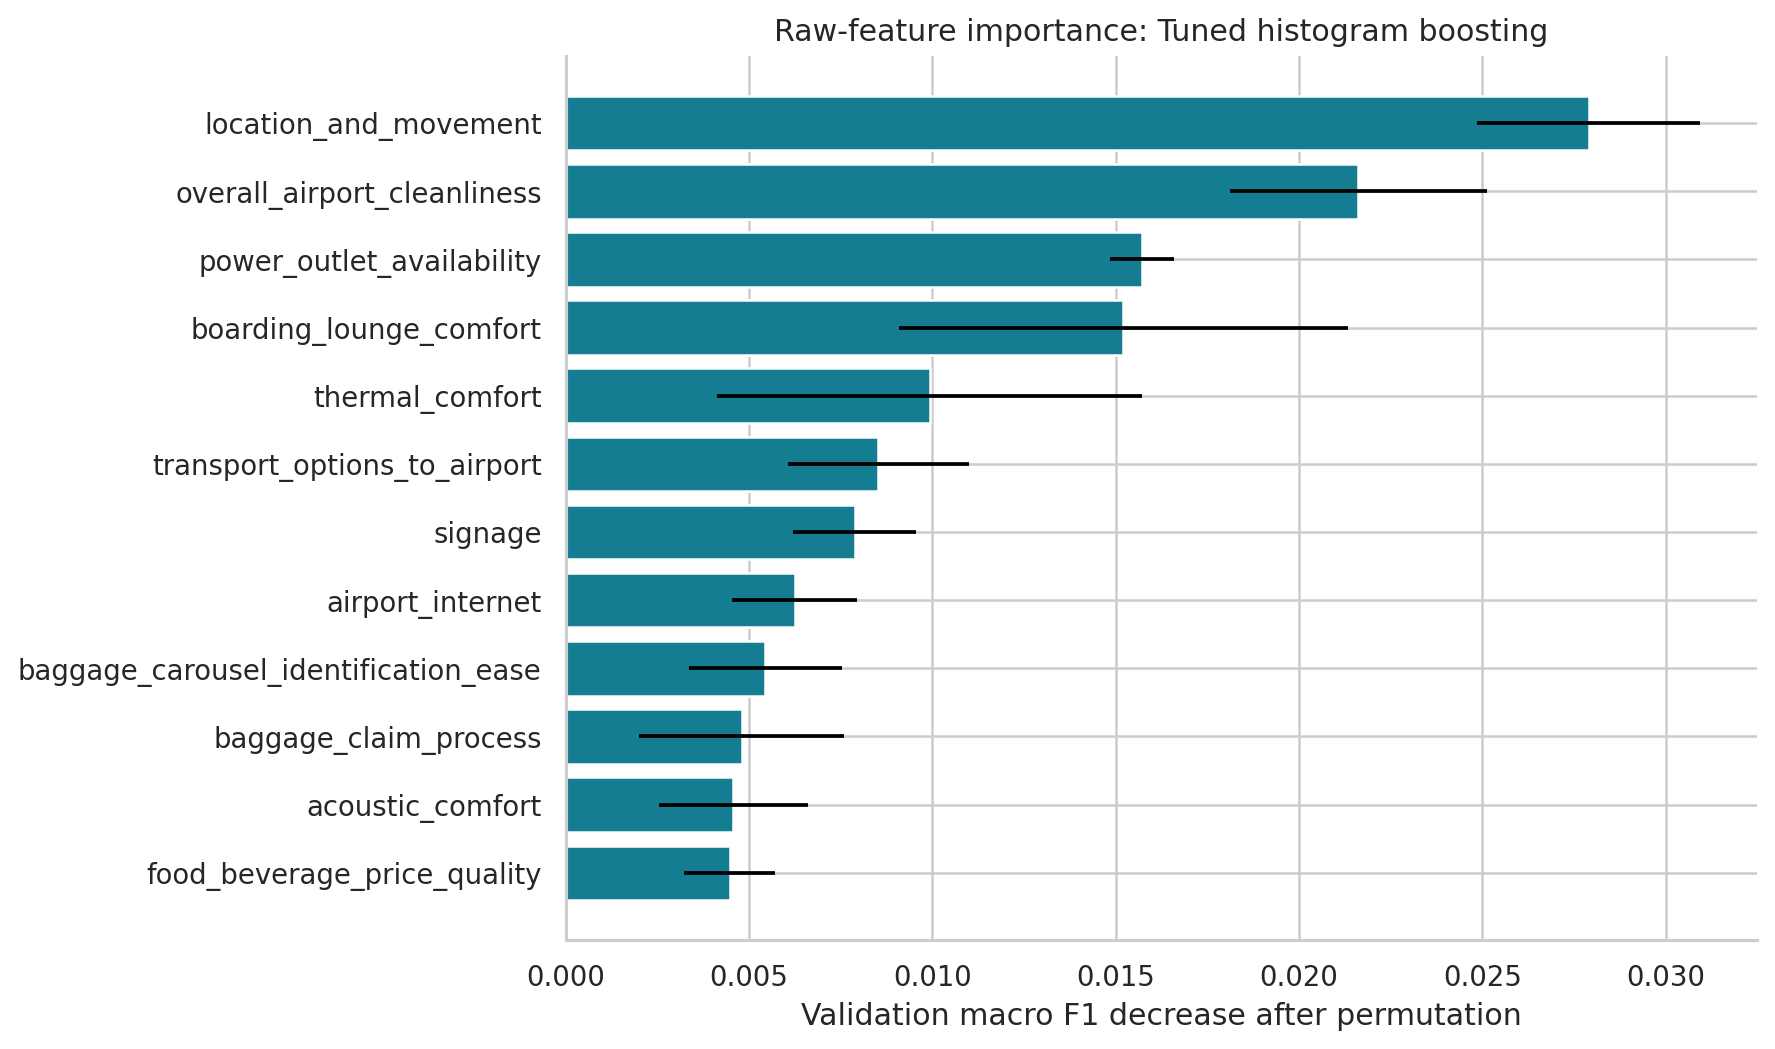

In [17]:
explanation_name=next(name for name in comparison.model if name in models)
explainer=models[explanation_name]
explain_idx=np.random.default_rng(SEED).choice(len(X_val),min(1200,len(X_val)),replace=False)
importance=permutation_importance(explainer,X_val.iloc[explain_idx],y_val.iloc[explain_idx],
    scoring='f1_macro',n_repeats=3,random_state=SEED,n_jobs=1)
importance_table=pd.DataFrame({'feature':X_val.columns,'importance_mean':importance.importances_mean,
    'importance_std':importance.importances_std}).sort_values('importance_mean',ascending=False)
table(importance_table.head(15),'importance_top15')
importance_table.to_csv(OUT/'tables/permutation_importance.csv',index=False)
fig,ax=plt.subplots(figsize=(10,6)); imp=importance_table.head(12).iloc[::-1]
ax.barh(imp.feature,imp.importance_mean,xerr=imp.importance_std,color='#147D92')
ax.set(xlabel='Validation macro F1 decrease after permutation',title=f'Raw-feature importance: {explanation_name}')
figure('13_feature_importance')

,attribute,group,n,positive_n,negative_n,accuracy,macro_f1,false_positive_rate,false_negative_rate,small_support
0,gender,Female,4317,1905,2412,0.8374,0.8357,0.1604,0.1654,False
1,gender,Male,4506,2026,2480,0.8398,0.8385,0.1569,0.1644,False
2,age_group,18 to 25 years,844,490,354,0.8531,0.8475,0.2119,0.1000,False
3,age_group,26 to 35 years,2268,1112,1156,0.8571,0.8571,0.1557,0.1295,False
4,age_group,36 to 45 years,1973,918,1055,0.8708,0.8701,0.1213,0.1383,False
5,age_group,46 to 55 years,1040,506,534,0.8596,0.8594,0.1236,0.1581,False
6,age_group,56 to 65 years,463,201,262,0.8510,0.8491,0.1489,0.1493,False
7,age_group,Over 65 years,125,61,64,0.8560,0.8555,0.2188,0.0656,False
8,age_group,nan,2110,643,1467,0.7687,0.7338,0.1868,0.3328,False
9,nationality,Brazilian,8478,3732,4746,0.8382,0.8363,0.1566,0.1685,False


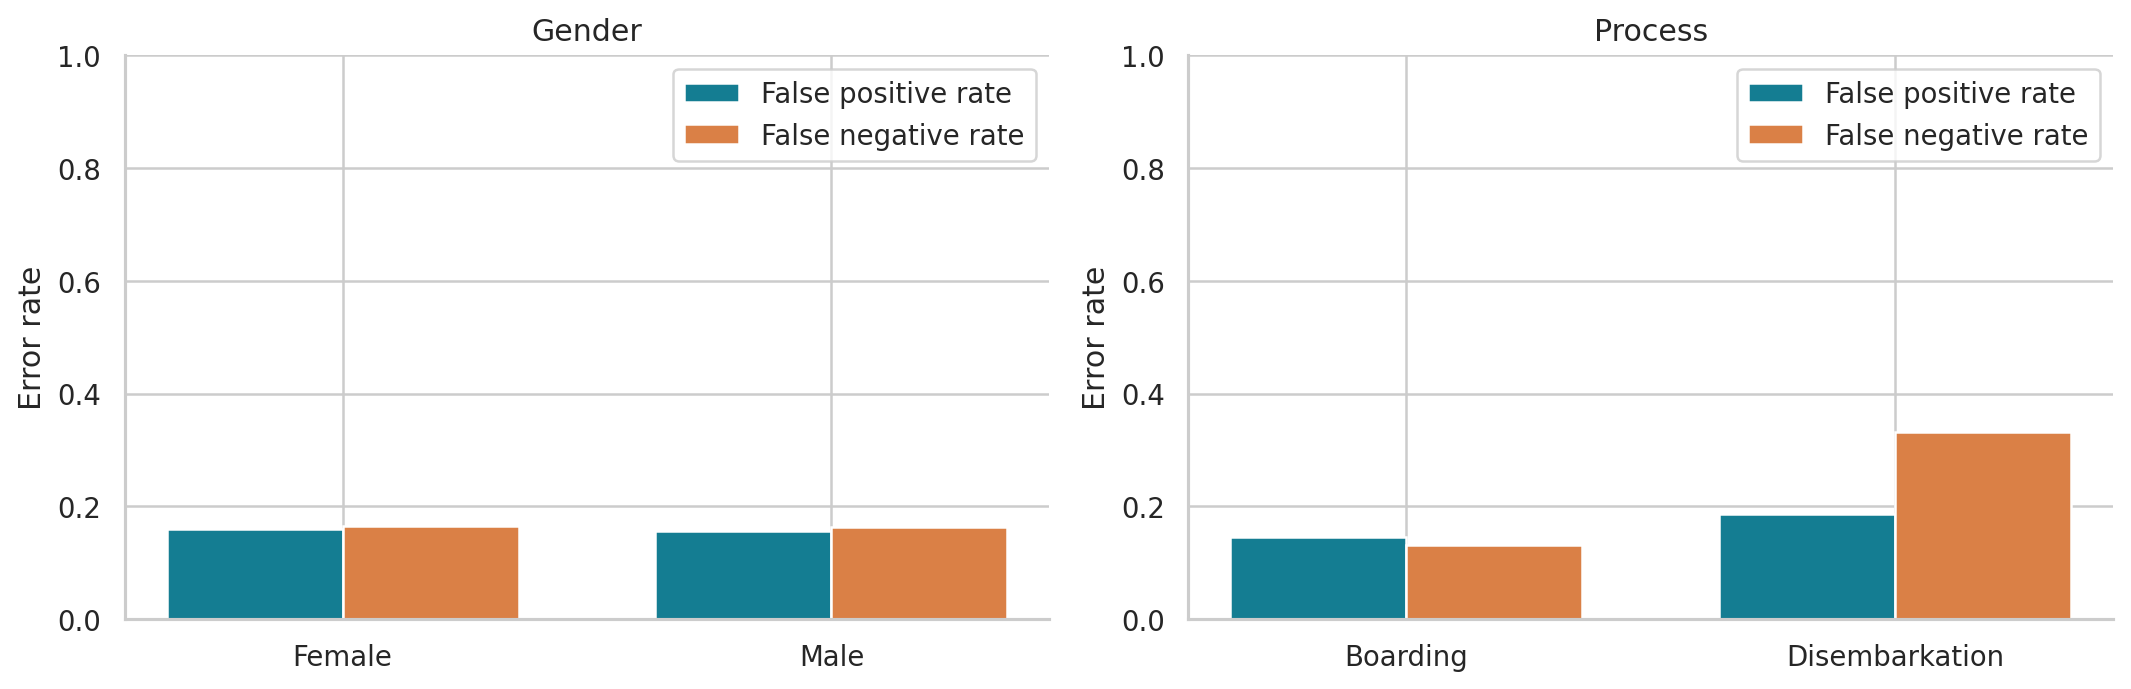

,source_row,process,flight_type,liked,predicted,score,boarding_lounge_comfort,overall_airport_cleanliness,baggage_claim_process,location_and_movement,confidence
35147,45601,Boarding,Domestic,1,0,0.0053,1.0,5.0,NaN,2.0,0.4947
1285,1329,Boarding,Domestic,1,0,0.0055,2.0,3.0,NaN,2.0,0.4945
11705,14014,Boarding,Domestic,1,0,0.0083,2.0,3.0,NaN,3.0,0.4917
36516,47491,Disembarkation,Domestic,1,0,0.0096,NaN,NaN,NaN,2.0,0.4904
40418,52856,Disembarkation,Domestic,1,0,0.0164,NaN,NaN,1.0,4.0,0.4836
13835,16796,Boarding,Domestic,1,0,0.0183,2.0,5.0,NaN,5.0,0.4817
2817,3021,Disembarkation,Domestic,1,0,0.0186,NaN,NaN,1.0,4.0,0.4814
15220,18613,Boarding,Domestic,1,0,0.0186,3.0,4.0,NaN,2.0,0.4814
42205,55327,Boarding,Domestic,1,0,0.0198,3.0,3.0,NaN,2.0,0.4802
19328,24093,Disembarkation,Domestic,1,0,0.0205,NaN,NaN,2.0,4.0,0.4795


In [18]:
audit=data.iloc[test_idx].copy(); audit['predicted']=chosen_pred; audit['score']=chosen_score
subgroups=[]
for column in ['gender','age_group','nationality','has_disability','process','flight_type']:
    for value,part in audit.groupby(column,dropna=False):
        actual=part.liked.to_numpy(); predicted=part.predicted.to_numpy()
        tn,fp,fn,tp=confusion_matrix(actual,predicted,labels=[0,1]).ravel()
        subgroups.append({'attribute':column,'group':str(value),'n':len(part),'positive_n':int((actual==1).sum()),
            'negative_n':int((actual==0).sum()),'accuracy':accuracy_score(actual,predicted),
            'macro_f1':f1_score(actual,predicted,labels=[0,1],average='macro',zero_division=0),
            'false_positive_rate':fp/(fp+tn) if fp+tn else np.nan,
            'false_negative_rate':fn/(fn+tp) if fn+tp else np.nan,
            'small_support':len(part)<100 or min(tp+fn,tn+fp)<30})
subgroups=pd.DataFrame(subgroups); table(subgroups,'subgroup_audit')
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,column in zip(axes,['gender','process']):
    part=subgroups[subgroups.attribute==column]
    positions=np.arange(len(part)); ax.bar(positions-.18,part.false_positive_rate,.36,label='False positive rate',color='#147D92')
    ax.bar(positions+.18,part.false_negative_rate,.36,label='False negative rate',color='#DA8046')
    ax.set_xticks(positions,part['group']); ax.set(title=column.title(),ylabel='Error rate',ylim=(0,1)); ax.legend()
figure('14_subgroup_errors')
errors=audit[audit.liked!=audit.predicted].copy()
error_columns=['source_row','process','flight_type','liked','predicted','score']+selected_ratings
table(errors[error_columns].assign(confidence=lambda t:abs(t.score-(.5 if is_probability else 0.))).sort_values('confidence',ascending=False).head(10),'high_confidence_errors')

### Limitations

Same-survey ratings support retrospective associations. Positive undersampling and deduplication change prevalence. Identical answers may come from different passengers. Survey routing can vary by airport or year, and small groups yield uncertain error rates. Independent airport and time identifiers would support a stronger test of generalization.

## 10. Save results

The `outputs/` folder contains the classical grid search, neural-network trials, feature-selection comparison, model-family comparison, and test results.

In [19]:
if best_name in models:
    joblib.dump(models[best_name], OUT/'models/selected_model.joblib')
summary = {'selected_model': best_name, 'validation_macro_f1': float(comparison.iloc[0].validation_macro_f1),
           'test': test_results.to_dict('records'), 'best_network_setting': best_nn_setting,
           'dataset_sha256': dataset_hash, 'seed': SEED}
(OUT/'summary.json').write_text(json.dumps(summary, indent=2))
print(f"{best_name}: validation macro F1 {comparison.iloc[0].validation_macro_f1:.4f}, test macro F1 {test_results.iloc[0].macro_f1:.4f}.")
print('Context-only validation macro F1:', round(all_scores.loc['Context-only boosting','macro_f1'], 4))


Tuned histogram boosting: validation macro F1 0.8330, test macro F1 0.8372.
Context-only validation macro F1: 0.5921
